# Imports

In [242]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
from datetime import timedelta
import scipy.stats as stats
import rasterio
from rasterio.transform import from_origin
from rasterio.features import rasterize
import geopandas as gpd
from shapely.geometry import Point
import requests
import random
import os
import math
import copy
import sys
import gc
from io import StringIO

In [243]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from numpy.lib.stride_tricks import sliding_window_view

from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import shap

import seaborn as sns

In [244]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
from datetime import timedelta
import scipy.stats as stats
import rasterio
from rasterio.transform import from_origin
from rasterio.features import rasterize
import geopandas as gpd
from shapely.geometry import Point
import requests
import random
import os
import math
import copy
import sys
import gc
from io import StringIO

In [245]:
from __future__ import annotations

import copy
import random
import time
from dataclasses import asdict, dataclass, field, replace
from typing import Any, Hashable, Mapping, Optional, Sequence

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

In [246]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from numpy.lib.stride_tricks import sliding_window_view

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import shap

import seaborn as sns

In [247]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Populate data_dict

In [248]:
path_to_data = "/content/drive/MyDrive/Year 2/Fall 2025/HONOR 3700/Data/Github/"
num_cases = 23

In [249]:
data_dict = {}

In [250]:
# Populate the dfs
for i in range(num_cases):
    if (i != 6):
        continue
    case_dict = {}
    case_dict["data_df"] = pd.read_csv(path_to_data + str(i) + "_data.csv")
    case_dict["metadata_df"] = pd.read_csv(path_to_data + str(i) + "_metadata.csv")

    data_dict[i] = case_dict

In [251]:
data_dict.keys()

dict_keys([6])

In [252]:
# Fine Tuning Stuff
# path_to_fine_tuning = "/content/drive/MyDrive/Year 2/Fall 2025/HONOR 3700/Data/Github/Fine Tuning"
# fine_tune_index = num_cases
# fine_tune_case_dict = {}
# fine_tune_case_dict["data_df"] = pd.read_csv(path_to_data + '6' + "_data.csv")
# fine_tune_case_dict["metadata_df"] = pd.read_csv(path_to_data + '6' + "_metadata.csv")

# data_dict[fine_tune_index] = fine_tune_case_dict

# num_cases += 1

In [253]:
# Populate lookups
for i in range(num_cases):
    if (i != 6):
        continue
    case_dict = data_dict[i]
    unique_points_df = case_dict['data_df'].drop_duplicates(subset=['fid'], keep='first')[["fid", "row_index", "col_index"]]
    case_dict["unique_points"] = unique_points_df
    case_dict["lookup"] = {(r,c):pid for r,c,pid in zip(unique_points_df.row_index, unique_points_df.col_index, unique_points_df.fid)}


In [254]:
# Expect size to be an odd integer
def get_patches(df, size, lookup):

    patches = []

    for r,c in zip(df.row_index, df.col_index):

        valid = True
        patch = []

        for dr in range(-(size // 2) , (size // 2)+1):
            row_vals = []
            for dc in range(-(size // 2) , (size // 2)+1):

                key = (r+dr, c+dc)

                if key not in lookup:
                    valid = False
                    break

                row_vals.append(lookup[key])

            if not valid:
                break

            patch.append(row_vals)

        if valid:
            patches.append(patch)

    patches = np.array(patches)

    return patches

In [255]:
PATCH_SIZE = 5

In [256]:
# Populate patches
for i in range(num_cases):
    if (i != 6):
        continue
    case_dict = data_dict[i]
    index_patches = get_patches(case_dict["unique_points"], PATCH_SIZE, case_dict["lookup"])
    case_dict["index_patches"] = index_patches

In [257]:
for i in range(num_cases):
    if (i != 6):
        continue
    if (len(data_dict[i]['index_patches']) == 0):
        print(i)

In [258]:
# Convert time in metadata to datetime, sort
for i in range(num_cases):
    if (i != 6):
        continue
    case_dict = data_dict[i]
    case_dict['metadata_df']['time'] = pd.to_datetime(case_dict['metadata_df']['time'])
    case_dict['metadata_df'] = case_dict['metadata_df'].sort_values(by='time', ascending=True)

In [259]:
def add_time_features(df):
    if df.empty:
        return
    df = df.copy()

    # Convert time strings to datetime
    t = pd.to_datetime(df["time"])

    # Basic date features
    df["year"] = t.dt.year
    df["month"] = t.dt.month
    df["day_of_year"] = t.dt.dayofyear

    # Seasonality
    df["seasonality"] = np.sin(
        2 * np.pi * df["day_of_year"] / 365
    )

    # Difference from previous observation, in days
    # df["diff_prev"] = (
    #     t.diff()
    #     .dt.total_seconds()
    #     .div(86400)
    #     .fillna(0)
    # )

    # Difference from first observation, in days
    # df["diff_first"] = (
    #     t - t.iloc[0]
    # ).dt.total_seconds().div(86400)

    return df

In [260]:
# Convert time in metadata to datetime, sort
for i in range(num_cases):
    if (i != 6):
        continue
    case_dict = data_dict[i]
    case_dict['metadata_df'] = add_time_features(case_dict['metadata_df'])

In [261]:
# Copy data dict that has non-zero rows for data and index_patches
data_dict_filtered = {
    i: case_dict
    for i, case_dict in data_dict.items()
    if (len(case_dict.get('unique_points', [])) > 0 and len(case_dict['index_patches'] > 0))
}

In [262]:
# Remove empty cases
list_of_empty_patches = [0, 2, 9, 16, 19]
for case_id in list_of_empty_patches:
    if (i != 6):
        continue
    _ = data_dict.pop(case_id)

In [263]:
data_dict.keys()

dict_keys([6])

In [264]:
similarity_url = "https://raw.githubusercontent.com/thomaslu678/Praxis-Lab-25-26/refs/heads/main/assets/studies/Case%20ID%20%2B%20Similarity.csv"
similarity_df = pd.read_csv(similarity_url)

In [265]:
fine_tune_row = pd.DataFrame([{'ID': 23, 'similarity': 1.0}])

# 2. Concatenate them together
similarity_df = pd.concat([similarity_df, fine_tune_row], ignore_index=True)

In [266]:
# Temp populate similiarity scores
for i in data_dict.keys():
    if (i != 6):
        continue
    case_dict = data_dict[i]
    case_dict['similarity_score'] = (similarity_df[similarity_df['ID'] == i]['similarity'].item())

In [267]:
for i in data_dict.keys():
    if (i != 6):
        continue
    data_dict[i]['metadata_df'] = data_dict[i]['metadata_df'].reset_index(drop=True)

In [268]:
bad_data_url = "https://raw.githubusercontent.com/thomaslu678/Praxis-Lab-25-26/refs/heads/main/assets/points/bad_data_fine_tune.csv"
bad_data_df = pd.read_csv(bad_data_url)

In [269]:
def remove_bad_data(data_dict, bad_data_df):
    report = []

    for case_id, bad_case_df in bad_data_df.groupby("case_id"):
        case_key = int(case_id)

        if case_key not in data_dict:
            report.append({
                "case_id": case_key,
                "bad_rows": len(bad_case_df),
                "matched": 0,
                "removed": 0,
                "unmatched": len(bad_case_df),
            })
            continue

        case_dict = data_dict[case_key]
        data_df = case_dict["data_df"]

        # Primary keys to remove
        bad_keys = set(
            zip(bad_case_df["fid"], bad_case_df["mission_id"])
        )

        # Identify rows matching those keys
        row_keys = list(zip(data_df["fid"], data_df["mission_id"]))
        mask = pd.Series(row_keys, index=data_df.index).isin(bad_keys)

        removed = int(mask.sum())

        # Update the dataframe in-place within the nested dict
        case_dict["data_df"] = data_df.loc[~mask].copy()

        report.append({
            "case_id": case_key,
            "bad_rows": len(bad_case_df),
            "matched": removed,
            "removed": removed,
            "unmatched": len(bad_case_df) - removed,
        })

    report_df = pd.DataFrame(report)

    return data_dict, report_df

In [270]:
data_dict, report_df = remove_bad_data(data_dict, bad_data_df)

In [271]:
report_df

,case_id,bad_rows,matched,removed,unmatched
0,1,1537,0,0,1537
1,3,7226,0,0,7226
2,4,2016,0,0,2016
3,5,4886,0,0,4886
4,6,2994,2994,2994,0
5,7,4443,0,0,4443
6,8,833,0,0,833
7,9,23,0,0,23
8,10,1872,0,0,1872
9,11,1996,0,0,1996


In [272]:
def populate_index_patch_metadata(data_dict):
    for case_id in data_dict.keys():
        case_data = data_dict[case_id]

        data_df = case_data["data_df"]
        metadata_df = case_data["metadata_df"].reset_index(drop=True)

        # Normalize FIDs once
        data_fids = data_df["fid"].astype(str)
        data_missions = data_df["mission_id"]

        # Build:
        #   mission_id -> set of FIDs available for that mission
        mission_to_fids = (
            data_df.assign(fid=data_fids)
            .groupby("mission_id")["fid"]
            .agg(set)
            .to_dict()
        )

        # Get the original patches
        index_patches = case_data["index_patches"]

        new_index_patches = []

        for index_patch in index_patches:
            # Flatten 2D patch and normalize FIDs
            patch_fids = set(str(fid) for fid in index_patch.flatten())

            # Find missions that contain every FID in the patch
            valid_mission_ids = [
                mission_id
                for mission_id, mission_fids in mission_to_fids.items()
                if patch_fids.issubset(mission_fids)
            ]

            # Convert mission IDs to metadata_df indices
            metadata_indices = metadata_df.index[
                metadata_df["mission_id"].isin(valid_mission_ids)
            ].tolist()

            new_index_patches.append({
                "data_indices": index_patch,
                "metadata_indices": metadata_indices,
            })

        # Replace original patches in place
        case_data["index_patches"] = new_index_patches

In [273]:
populate_index_patch_metadata(data_dict)

In [274]:
data_dict.keys()

dict_keys([6])

In [275]:
data_dict[6].keys()

dict_keys(['data_df', 'metadata_df', 'unique_points', 'lookup', 'index_patches', 'similarity_score'])

# Instantiate model with weights

# Handle Tree Stuff

## Load datasets for tree patches

## Process zonal stats

In [35]:
zonal_stats_df = pd.read_csv('/content/drive/MyDrive/Year 2/Fall 2025/HONOR 3700/Data/Github/Trees/zonal_stats.csv')

In [36]:
zonal_stats_df

,grid_id,row_index,col_index,red_count,red_sum,red_mean,green_count,green_sum,green_mean,blue_count,blue_sum,blue_mean,nir_count,nir_sum,nir_mean
0,8,0,8,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000
1,9,0,9,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000
2,10,0,10,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000
3,11,0,11,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000
4,12,0,12,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000,2500,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6154,8469,104,45,2500,441.566650,0.176627,2500,416.443407,0.166577,2500,287.780685,0.115112,2500,606.918517,0.242767
6155,8470,104,46,2500,433.673856,0.173470,2500,410.755080,0.164302,2500,282.782324,0.113113,2500,594.004600,0.237602
6156,8471,104,47,2500,409.950501,0.163980,2500,390.911524,0.156365,2500,265.530274,0.106212,2500,551.322975,0.220529
6157,8472,104,48,2500,406.788552,0.162715,2500,385.810098,0.154324,2500,257.019813,0.102808,2500,567.551559,0.227021


In [37]:
print(zonal_stats_df['red_count'].unique(),
      zonal_stats_df['green_count'].unique(),
      zonal_stats_df['blue_count'].unique(),
      zonal_stats_df['nir_count'].unique())

[2500] [2500] [2500] [2500]


## Process RGBALL

In [38]:
rgbn_df = pd.read_csv('/content/drive/MyDrive/Year 2/Fall 2025/HONOR 3700/Data/Github/Trees/rgbn_grid_radii.csv')

In [39]:
rgbn_df

,Red,Green,Blue,NIR,grid_id,radii_id
0,0.209046,0.194738,0.113210,0.272854,3179.0,1
1,0.204406,0.190381,0.107538,0.272601,3179.0,1
2,0.214384,0.198910,0.123468,0.273802,3179.0,1
3,0.209956,0.192596,0.106904,0.273536,3179.0,1
4,0.201147,0.187533,0.105403,0.268976,3179.0,1
...,...,...,...,...,...,...
355488,0.165053,0.141445,0.037082,0.244995,1568.0,3008
355489,0.169394,0.145628,0.052126,0.245158,1568.0,3008
355490,0.163303,0.147246,0.060376,0.241471,1568.0,3008
355491,0.165974,0.145628,0.060376,0.241471,1568.0,3008


In [40]:
rgbn_df['grid_id'].isna().sum()

np.int64(601)

In [41]:
rgbn_df = rgbn_df.dropna()

In [42]:
rgbn_df.isna().sum()

,0
Red,0
Green,0
Blue,0
NIR,0
grid_id,0
radii_id,0


In [43]:
rgbn_df['grid_id'].dtype

dtype('float64')

In [44]:
rgbn_df['grid_id'] = rgbn_df['grid_id'].astype(int)

/tmp/ipykernel_672/554811330.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rgbn_df['grid_id'] = rgbn_df['grid_id'].astype(int)


In [45]:
rgbn_df['grid_id']

,grid_id
0,3179
1,3179
2,3179
3,3179
4,3179
...,...
355488,1568
355489,1568
355490,1568
355491,1568


## Process radii df

In [46]:
radii_df = pd.read_csv('/content/drive/MyDrive/Year 2/Fall 2025/HONOR 3700/Data/Github/Trees/trees_species_dbh_grid.csv')

In [47]:
radii_df.rename(columns={'fid': 'radii_id'}, inplace=True)

In [48]:
radii_df

,radii_id,SPP,DBH,grid_id
0,1,Zelkova serrata,10,3179
1,2,Zelkova species,12,3260
2,3,Zelkova species,9,3341
3,4,Zelkova species,10,3341
4,5,Zelkova species,9,3341
...,...,...,...,...
3003,3004,Gleditsia triacanthos,13,949
3004,3005,Tilia cordata,19,525
3005,3006,Pyrus calleryana,2,1567
3006,3007,Pyrus calleryana,2,1568


In [49]:
radii_df.isna().sum()

,0
radii_id,0
SPP,0
DBH,0
grid_id,0


## Process grids

In [50]:
zonal_stats_df.columns

Index(['grid_id', 'row_index', 'col_index', 'red_count', 'red_sum', 'red_mean',
       'green_count', 'green_sum', 'green_mean', 'blue_count', 'blue_sum',
       'blue_mean', 'nir_count', 'nir_sum', 'nir_mean'],
      dtype='object')

In [51]:
grids_df = zonal_stats_df[['grid_id', 'row_index', 'col_index']].copy()

In [52]:
grids_df

,grid_id,row_index,col_index
0,8,0,8
1,9,0,9
2,10,0,10
3,11,0,11
4,12,0,12
...,...,...,...
6154,8469,104,45
6155,8470,104,46
6156,8471,104,47
6157,8472,104,48


In [53]:
grids_df['grid_id'].isna().sum()

np.int64(0)

In [54]:
np.min(grids_df['grid_id'])

8

In [55]:
np.max(grids_df['grid_id'])

8473

## Process radii to grid id

In [56]:
radii_df.columns

Index(['radii_id', 'SPP', 'DBH', 'grid_id'], dtype='object')

In [57]:
radii_to_grid_df = radii_df[['radii_id', 'grid_id']].copy()

In [58]:
radii_to_grid_df

,radii_id,grid_id
0,1,3179
1,2,3260
2,3,3341
3,4,3341
4,5,3341
...,...,...
3003,3004,949
3004,3005,525
3005,3006,1567
3006,3007,1568


In [59]:
radii_to_grid_df['grid_id'].isna().sum()

np.int64(0)

In [60]:
radii_to_grid_df['grid_id'].dtype

dtype('int64')

In [61]:
radii_to_grid_df['grid_id'] = radii_to_grid_df['grid_id'].astype(int)

In [62]:
radii_to_grid_df['grid_id'].dtype

dtype('int64')

## Confirm alignment

In [63]:
# zonal_stats_df
# grids_df
# radii_df
# rgbn_df

In [64]:
print("Grids: ", np.min(zonal_stats_df['grid_id']), np.max(zonal_stats_df['grid_id']))

Grids:  8 8473


In [65]:
print("Grids: ", np.min(grids_df['grid_id']), np.max(grids_df['grid_id']))

Grids:  8 8473


In [66]:
print("Radii: ", np.min(radii_df['radii_id']), np.max(radii_df['radii_id']))

Radii:  1 3008


In [67]:
print("Grids: ", np.min(rgbn_df['grid_id']), np.max(rgbn_df['grid_id']))

Grids:  469 8464


In [68]:
print("Radii: ", np.min(rgbn_df['radii_id']), np.max(rgbn_df['radii_id']))

Radii:  1 3008


In [69]:
# 1. Check if all in zonal_stats_df
check1 = rgbn_df['grid_id'].isin(zonal_stats_df['grid_id']).all()

# 2. Check if all in grids_df
check2 = rgbn_df['grid_id'].isin(grids_df['grid_id']).all()

# 3. Final check: True if both conditions are met
all_present = check1 and check2

print(f"All present: {all_present}")

All present: True


In [70]:
print(f"All present: {rgbn_df['radii_id'].isin(radii_df['radii_id']).all()}")

All present: True


In [71]:
print(len(rgbn_df[rgbn_df['radii_id'].isin(radii_df['radii_id'])]))
print(len(rgbn_df[~rgbn_df['radii_id'].isin(radii_df['radii_id'])]))
print(len(rgbn_df))

354892
0
354892


In [72]:
rgbn_df = rgbn_df[rgbn_df['radii_id'].isin(radii_df['radii_id'])]

In [73]:
print(f"All present: {rgbn_df['radii_id'].isin(radii_df['radii_id']).all()}")

All present: True


In [74]:
print(f"All present: {radii_df['radii_id'].isin(radii_to_grid_df['radii_id']).all()}")

All present: True


## Prepare processing tree patches

In [75]:
# zonal_stats_df
# grids_df
# radii_df
# rgbn_df

In [76]:
filtered_radii_df = radii_df[radii_df['radii_id'].isin(rgbn_df['radii_id'])].copy()

In [77]:
radii_df

,radii_id,SPP,DBH,grid_id
0,1,Zelkova serrata,10,3179
1,2,Zelkova species,12,3260
2,3,Zelkova species,9,3341
3,4,Zelkova species,10,3341
4,5,Zelkova species,9,3341
...,...,...,...,...
3003,3004,Gleditsia triacanthos,13,949
3004,3005,Tilia cordata,19,525
3005,3006,Pyrus calleryana,2,1567
3006,3007,Pyrus calleryana,2,1568


In [78]:
filtered_radii_df

,radii_id,SPP,DBH,grid_id
0,1,Zelkova serrata,10,3179
1,2,Zelkova species,12,3260
2,3,Zelkova species,9,3341
3,4,Zelkova species,10,3341
4,5,Zelkova species,9,3341
...,...,...,...,...
3003,3004,Gleditsia triacanthos,13,949
3004,3005,Tilia cordata,19,525
3005,3006,Pyrus calleryana,2,1567
3006,3007,Pyrus calleryana,2,1568


In [79]:
filtered_radii_df.isna().sum()

,0
radii_id,0
SPP,0
DBH,0
grid_id,0


In [80]:
filtered_radii_df['grid_id'].dtype

dtype('int64')

In [81]:
filtered_radii_df['grid_id'] = filtered_radii_df['grid_id'].astype(int)

In [82]:
filtered_radii_df['grid_id'].dtype

dtype('int64')

In [83]:
filtered_radii_df

,radii_id,SPP,DBH,grid_id
0,1,Zelkova serrata,10,3179
1,2,Zelkova species,12,3260
2,3,Zelkova species,9,3341
3,4,Zelkova species,10,3341
4,5,Zelkova species,9,3341
...,...,...,...,...
3003,3004,Gleditsia triacanthos,13,949
3004,3005,Tilia cordata,19,525
3005,3006,Pyrus calleryana,2,1567
3006,3007,Pyrus calleryana,2,1568


## Process raw data into grid/radii id before/after

In [84]:
# Initialize list to collect results
rows = []

In [85]:
subset = rgbn_df[rgbn_df['radii_id'] == 1]

In [86]:
subset

,Red,Green,Blue,NIR,grid_id,radii_id
0,0.209046,0.194738,0.113210,0.272854,3179,1
1,0.204406,0.190381,0.107538,0.272601,3179,1
2,0.214384,0.198910,0.123468,0.273802,3179,1
3,0.209956,0.192596,0.106904,0.273536,3179,1
4,0.201147,0.187533,0.105403,0.268976,3179,1
...,...,...,...,...,...,...
112,0.223045,0.209867,0.144034,0.276180,3179,1
113,0.203237,0.186965,0.101950,0.275078,3179,1
114,0.210689,0.198542,0.120355,0.275691,3179,1
115,0.216111,0.201571,0.129756,0.273536,3179,1


In [87]:
pix = subset[subset['grid_id'] == 4713]

In [88]:
pix

,Red,Green,Blue,NIR,grid_id,radii_id


In [89]:
zonal_stats_df[zonal_stats_df['grid_id'] == 4713].iloc[0]

,3321
grid_id,4713.000000
row_index,58.000000
col_index,15.000000
red_count,2500.000000
red_sum,482.317792
red_mean,0.192927
green_count,2500.000000
green_sum,444.910008
green_mean,0.177964
blue_count,2500.000000


In [90]:
pix['Red'].sum()

np.float64(0.0)

In [91]:
# Loop over each radius (fid)
for fid in filtered_radii_df['radii_id'].unique():

    # Subset rgbn_df for this radii_id
    subset = rgbn_df[rgbn_df['radii_id'] == fid]

    # Get unique grid_ids for this radius
    grid_ids = subset['grid_id'].unique()

    for gid in grid_ids:

        # Subset pixels for this grid_id + radii_id
        pix = subset[subset['grid_id'] == gid]

        # Get zonal stats row
        zs_row = zonal_stats_df[zonal_stats_df['grid_id'] == gid].iloc[0]

        # BEFORE values (means already computed)
        before_red = zs_row['red_mean']
        before_green = zs_row['green_mean']
        before_blue = zs_row['blue_mean']
        before_nir = zs_row['nir_mean']

        # ORIGINAL sums
        red_sum = zs_row['red_sum']
        green_sum = zs_row['green_sum']
        blue_sum = zs_row['blue_sum']
        nir_sum = zs_row['nir_sum']

        red_count = zs_row['red_count']
        green_count = zs_row['green_count']
        blue_count = zs_row['blue_count']
        nir_count = zs_row['nir_count']

        # Remove pixels inside radius
        removed_count = len(pix)

        # Subtract pixel values
        new_red_sum = red_sum - pix['Red'].sum()
        new_green_sum = green_sum - pix['Green'].sum()
        new_blue_sum = blue_sum - pix['Blue'].sum()
        new_nir_sum = nir_sum - pix['NIR'].sum()

        # AFTER means
        after_red = new_red_sum / (red_count - removed_count) if red_count > 0 else None
        after_green = new_green_sum / (green_count - removed_count) if green_count > 0 else None
        after_blue = new_blue_sum / (blue_count - removed_count) if blue_count > 0 else None
        after_nir = new_nir_sum / (nir_count - removed_count) if nir_count > 0 else None

        # Append result
        rows.append({
            'grid_id': gid,
            'radii_id': fid,
            'before_red': before_red,
            'after_red': after_red,
            'before_green': before_green,
            'after_green': after_green,
            'before_blue': before_blue,
            'after_blue': after_blue,
            'before_nir': before_nir,
            'after_nir': after_nir
        })

In [92]:
# Create final dataframe
result_df = pd.DataFrame(rows)

In [93]:
result_df

,grid_id,radii_id,before_red,after_red,before_green,after_green,before_blue,after_blue,before_nir,after_nir
0,3179,1,0.206899,0.206892,0.193059,0.193027,0.115139,0.115065,0.270782,0.270768
1,3260,2,0.195428,0.195552,0.180035,0.180312,0.098392,0.099081,0.262536,0.262468
2,3341,3,0.195303,0.195197,0.179745,0.179697,0.097258,0.097526,0.261336,0.261111
3,3341,4,0.195303,0.195444,0.179745,0.180053,0.097258,0.097853,0.261336,0.261181
4,3341,5,0.195303,0.195530,0.179745,0.180183,0.097258,0.097996,0.261336,0.261305
...,...,...,...,...,...,...,...,...,...,...
4114,950,3004,0.203356,0.203380,0.182451,0.182508,0.137598,0.137682,0.277749,0.277664
4115,525,3005,0.186331,0.186107,0.170221,0.170260,0.080206,0.080281,0.261865,0.261632
4116,1567,3006,0.201844,0.201953,0.190481,0.190616,0.123607,0.123810,0.259652,0.259705
4117,1568,3007,0.191359,0.191453,0.175122,0.175230,0.101810,0.101964,0.258648,0.258696


In [94]:
len(result_df['radii_id'].unique())

2894

## Update correct grid_id values of result_df

In [95]:
# 1. Get reference dataframe
unique_points = data_dict[6]['unique_points']

# 2. Create mapping by matching row_index and col_index
mapping_df = grids_df.merge(
    unique_points[['fid', 'row_index', 'col_index']],
    on=['row_index', 'col_index'],
    how='left'
)

# 3. Report missing mappings
missing_mappings = mapping_df[mapping_df['fid'].isna()]

if not missing_mappings.empty:
    print(f"Discarding {len(missing_mappings)} grid IDs with missing mappings:")
    print(missing_mappings[['grid_id', 'row_index', 'col_index']])

Discarding 141 grid IDs with missing mappings:
      grid_id  row_index  col_index
22         30          0         30
23         31          0         31
24         32          0         32
25         33          0         33
26         34          0         34
...       ...        ...        ...
6129     8404        103         61
6130     8405        103         62
6131     8406        103         63
6132     8407        103         64
6133     8408        103         65

[141 rows x 3 columns]


In [156]:
grids_df

,grid_id,row_index,col_index
0,8,0,8
1,9,0,9
2,10,0,10
3,11,0,11
4,12,0,12
...,...,...,...
6154,8469,104,45
6155,8470,104,46
6156,8471,104,47
6157,8472,104,48


In [96]:
# 4. Create mapping dictionary (old grid_id -> new fid)
grid_mapping = (
    mapping_df
    .dropna(subset=['fid'])
    .set_index('grid_id')['fid']
    .to_dict()
)

# 5. Make a copy of result_df
updated_result_df = result_df.copy()

# 6. Remove rows whose grid_id has no valid mapping
updated_result_df = updated_result_df[
    updated_result_df['grid_id'].isin(grid_mapping.keys())
].copy()

# 7. Replace old grid_id values with new fid values
updated_result_df['grid_id'] = updated_result_df['grid_id'].map(grid_mapping)

# 8. Report results
print(f"\nOriginal rows: {len(result_df)}")
print(f"Updated rows:  {len(updated_result_df)}")
print(f"Discarded rows: {len(result_df) - len(updated_result_df)}")


Original rows: 4119
Updated rows:  4087
Discarded rows: 32


In [98]:
updated_result_df

,grid_id,radii_id,before_red,after_red,before_green,after_green,before_blue,after_blue,before_nir,after_nir
0,2617,1,0.206899,0.206892,0.193059,0.193027,0.115139,0.115065,0.270782,0.270768
1,2666,2,0.195428,0.195552,0.180035,0.180312,0.098392,0.099081,0.262536,0.262468
2,2715,3,0.195303,0.195197,0.179745,0.179697,0.097258,0.097526,0.261336,0.261111
3,2715,4,0.195303,0.195444,0.179745,0.180053,0.097258,0.097853,0.261336,0.261181
4,2715,5,0.195303,0.195530,0.179745,0.180183,0.097258,0.097996,0.261336,0.261305
...,...,...,...,...,...,...,...,...,...,...
4114,892,3004,0.203356,0.203380,0.182451,0.182508,0.137598,0.137682,0.277749,0.277664
4115,473,3005,0.186331,0.186107,0.170221,0.170260,0.080206,0.080281,0.261865,0.261632
4116,1501,3006,0.201844,0.201953,0.190481,0.190616,0.123607,0.123810,0.259652,0.259705
4117,1502,3007,0.191359,0.191453,0.175122,0.175230,0.101810,0.101964,0.258648,0.258696


In [99]:
set(updated_result_df['grid_id'].unique()) <= set(unique_points['fid'].unique())

True

## Remove trees/NAIP values with grid not pulled into 6's landsat

In [220]:
mapping_df

,grid_id,row_index,col_index,fid
0,8,0,8,0.0
1,9,0,9,1.0
2,10,0,10,2.0
3,11,0,11,3.0
4,12,0,12,4.0
...,...,...,...,...
6154,8469,104,45,6154.0
6155,8470,104,46,6155.0
6156,8471,104,47,6156.0
6157,8472,104,48,6157.0


In [188]:
invalid_old_grid_ids = mapping_df[mapping_df['fid'].isna()]['grid_id'].unique()

In [192]:
clean_radii_df = filtered_radii_df.copy()

In [193]:
clean_radii_df = clean_radii_df[~clean_radii_df['grid_id'].isin(invalid_old_grid_ids)]

In [194]:
clean_radii_df

,radii_id,SPP,DBH,grid_id
0,1,Zelkova serrata,10,3179
1,2,Zelkova species,12,3260
2,3,Zelkova species,9,3341
3,4,Zelkova species,10,3341
4,5,Zelkova species,9,3341
...,...,...,...,...
3003,3004,Gleditsia triacanthos,13,949
3004,3005,Tilia cordata,19,525
3005,3006,Pyrus calleryana,2,1567
3006,3007,Pyrus calleryana,2,1568


## Match with data_dict

In [100]:
metadata_df = data_dict[6]['metadata_df']

In [101]:
metadata_df

,mission_id,time,cloud_cover,sun_azimuth,sun_elevation,year,month,day_of_year,seasonality
0,LC08_038032_20210106,2021-01-06 18:08:26,0.98,158.341629,24.186889,2021,1,6,0.103102
1,LE07_038032_20210114,2021-01-14 17:25:43,2.00,146.995718,21.244629,2021,1,14,0.238673
2,LC08_038032_20210122,2021-01-22 18:08:20,93.14,155.921619,26.515455,2021,1,22,0.369725
3,LE07_038032_20210130,2021-01-30 17:24:34,41.00,143.946674,23.972660,2021,1,30,0.493776
4,LC08_038032_20210207,2021-02-07 18:08:18,1.49,153.566370,30.478502,2021,2,38,0.608477
...,...,...,...,...,...,...,...,...,...
261,LC09_038032_20251125,2025-11-25 18:08:32,2.75,162.575198,26.841635,2025,11,329,-0.580800
262,LC08_038032_20251203,2025-12-03 18:08:26,51.00,162.200034,25.404337,2025,12,337,-0.463550
263,LC09_038032_20251211,2025-12-11 18:08:31,1.28,161.608208,24.379769,2025,12,345,-0.337523
264,LC08_038032_20251219,2025-12-19 18:08:27,97.14,160.752412,23.781978,2025,12,353,-0.205104


In [102]:
naip_landsat_id = 'LC08_038032_20211106'

In [103]:
metadata_df[metadata_df['mission_id'] == naip_landsat_id]

,mission_id,time,cloud_cover,sun_azimuth,sun_elevation,year,month,day_of_year,seasonality
37,LC08_038032_20211106,2021-11-06 18:08:36,73.2,162.209935,31.602343,2021,11,310,-0.811539


# 16_VIT Config

In [276]:
BAND_COLUMNS = ("Blue", "Green", "Red", "NIR")
METADATA_COLUMNS = (
    "cloud_cover", "sun_azimuth", "sun_elevation", "year", "month",
    "day_of_year", "seasonality",
)
WINDOW_TIME_COLUMNS = ("diff_prev", "diff_first")

In [277]:
@dataclass(frozen=True)
class WorkflowConfig:
    window: int = 50
    # Set to None to retain every possible consecutive window for every patch.
    samples_per_patch: Optional[int] = 10
    # Required. This case is untouched until the best validation model is chosen.
    test_case_id: Optional[Hashable] = None
    # Optional adaptation case, excluded from initial train/validation/test.
    fine_tune_case_id: Optional[Hashable] = None
    # Fraction of the remaining case IDs assigned to validation.
    validation_fraction: float = 0.2
    train_subset_fraction: float = 1.0
    validation_subset_fraction: float = 1.0
    validation_subset_seed: int = 1026
    # The fine-tune case is first split by patch, then optionally subsampled.
    fine_tune_validation_fraction: float = 0.2
    fine_tune_subset_fraction: float = 1.0
    fine_tune_validation_subset_fraction: float = 1.0
    fine_tune_split_seed: int = 1027
    fine_tune_subset_seed: int = 1028
    batch_size: int = 8
    num_epochs: int = 20
    learning_rate: float = 3e-4
    weight_decay: float = 1e-4
    num_workers: int = 4
    # Training randomness is independent of case splitting/subset selection.
    seed: int = 1024
    split_seed: int = 1024
    subset_seed: int = 1025
    accum_steps: int = 1
    use_amp: bool = True
    amp_dtype: str = "float16"       # float16 | bfloat16
    enable_tf32: bool = True
    compile_model: bool = False      # PyTorch 2.x; useful for longer runs
    compile_mode: str = "default"    # default | reduce-overhead | max-autotune
    fused_optimizer: bool = True     # fused AdamW when CUDA/PyTorch support it
    max_grad_norm: Optional[float] = None
    early_stopping_patience: Optional[int] = 6
    early_stopping_min_delta_K: float = 0.0
    # Fine-tuning defaults: smaller LR, shorter patience, optional freezing.
    fine_tune_num_epochs: int = 10
    fine_tune_learning_rate: float = 3e-5
    fine_tune_weight_decay: float = 1e-4
    fine_tune_early_stopping_patience: Optional[int] = 3
    fine_tune_early_stopping_min_delta_K: float = 0.0
    fine_tune_freeze_mode: str = "spatial"  # none | spatial | backbone
    pin_memory: bool = True
    persistent_workers: bool = True
    prefetch_factor: int = 2
    cuda_prefetch: bool = True
    drop_last_train: bool = False
    # Derived only after a patch-specific window has been chosen. Values are days.
    include_window_time_deltas: bool = True
    # Eight unique D4 transforms: 4 rotations x {no reflection, reflection}.
    augment_train_d4: bool = True
    # gpu expands each loaded base batch to 8 variants after one H2D transfer.
    # dataset preserves the older behavior of loading each variant separately.
    d4_augmentation_backend: str = "gpu"  # gpu | dataset
    # Regression objective and train-label-only imbalance handling.
    loss_function: str = "mse"  # mse | mae | huber | log_cosh | mse_ccc | tail_weighted_mse
    huber_delta_K: float = 2.0
    ccc_weight: float = 0.25
    train_sampling_strategy: str = "uniform"  # uniform | tail_oversample
    tail_fraction: float = 0.10
    tail_side: str = "both"       # both | lower | upper
    tail_sampling_multiplier: float = 4.0
    tail_loss_multiplier: float = 4.0
    # Makes each case's total loss influence proportional to similarity_score,
    # rather than similarity_score multiplied by its number of samples.
    case_balance_by_similarity: bool = True
    # Progress logging; set an interval to None or 0 to disable that loop's logs.
    progress_case_logging: bool = True
    train_progress_interval: Optional[int] = 10000
    eval_progress_interval: Optional[int] = 1000
    # Architecture switches used by run_experiments.
    spatial_position_mode: str = "local"  # none | local | global | local_global
    spatial_pooling: str = "center_mean"   # center_mean | cls
    temporal_architecture: str = "encoder" # encoder | causal
    temporal_pooling: str = "attention"    # attention | cls | last
    use_center_skip: bool = True
    d_model: int = 64
    spatial_heads: int = 4
    spatial_layers: int = 1
    temporal_heads: int = 4
    temporal_layers: int = 2
    ff_multiplier: int = 4
    dropout: float = 0.1
    input_noise_std: float = 0.0  # normalized training inputs only
    # True implements "if any pixel is missing, discard the patch" over every
    # selected window. False discards only each incomplete sample window.
    discard_entire_patch_if_incomplete: bool = True


@dataclass
class PreparedCase:
    case_id: Hashable
    missions: np.ndarray                 # [M]
    times: np.ndarray                    # [M], datetime64[ns]
    bands: np.ndarray                    # [M, P, C]
    lst: np.ndarray                      # [M, P]
    metadata: np.ndarray                 # [M, E]
    fid_to_pos: dict[Any, int]
    pixel_coords: np.ndarray              # [P, 2], case-relative row/column in [-1, 1]
    patches: np.ndarray                  # [N, H, W], integer positions into P
    patch_metadata_indices: tuple[np.ndarray, ...]  # per-patch metadata iloc values
    similarity_score: float


@dataclass(frozen=True)
class SampleRef:
    case_id: Hashable
    patch_idx: int
    start: int


@dataclass(frozen=True)
class NormalizationStats:
    cube_mean: np.ndarray
    cube_std: np.ndarray
    emb_mean: np.ndarray
    emb_std: np.ndarray
    y_mean: float
    y_std: float


@dataclass
class PreparedWorkflow:
    """Reusable expensive state shared by repeated training runs."""
    cases: dict[Hashable, PreparedCase]
    train_case_ids: list[Hashable]
    val_case_ids: list[Hashable]
    test_case_ids: list[Hashable]
    fine_tune_case_ids: list[Hashable]
    full_train_refs: list[SampleRef]
    val_refs: list[SampleRef]
    test_refs: list[SampleRef]
    full_fine_tune_train_refs: list[SampleRef]
    full_fine_tune_val_refs: list[SampleRef]
    train_report: dict[Hashable, dict[str, Any]]
    val_report: dict[Hashable, dict[str, Any]]
    test_report: dict[Hashable, dict[str, Any]]
    fine_tune_report: dict[Hashable, dict[str, Any]]
    preparation_signature: tuple[Any, ...]
    # Maps (subset_fraction, subset_seed, time-delta flag) to cached state.
    subset_cache: dict[tuple[Any, ...], tuple[list[SampleRef], NormalizationStats,
                                                dict[Hashable, dict[str, float]]]] = field(
        default_factory=dict, repr=False
    )
    target_cache: dict[tuple[float, int], np.ndarray] = field(
        default_factory=dict, repr=False
    )


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def evenly_spaced_starts(
    num_times: int, window: int, count: Optional[int]
) -> np.ndarray:
    """Return selected starts spanning [0, num_times-window].

    ``count=None`` returns every possible start. If fewer than ``count``
    distinct windows exist, all distinct starts are used. Duplicate samples
    are deliberately not created.
    """
    max_start = num_times - window
    if max_start < 0:
        return np.empty(0, dtype=np.int64)
    if count is None:
        return np.arange(max_start + 1, dtype=np.int64)
    if count <= 0:
        raise ValueError("samples_per_patch must be positive or None")
    n = min(count, max_start + 1)
    return np.unique(np.rint(np.linspace(0, max_start, n)).astype(np.int64))


def _require_columns(df: pd.DataFrame, columns: Sequence[str], label: str) -> None:
    missing = sorted(set(columns) - set(df.columns))
    if missing:
        raise ValueError(f"{label} is missing columns: {missing}")


def prepare_case(
    case_id: Hashable,
    case: Mapping[str, Any],
    band_columns: Sequence[str] = BAND_COLUMNS,
    metadata_columns: Sequence[str] = METADATA_COLUMNS,
) -> PreparedCase:
    """Validate one case and convert DataFrames to dense read-only arrays."""
    for key in ("data_df", "metadata_df", "index_patches", "similarity_score"):
        if key not in case:
            raise ValueError(f"Case {case_id!r} is missing key {key!r}")

    data = case["data_df"]
    meta = case["metadata_df"].copy()
    _require_columns(
        data,
        ("fid", "row_index", "col_index", "mission_id", "LST_K", *band_columns),
        "data_df",
    )
    _require_columns(meta, ("mission_id", "time", *metadata_columns), "metadata_df")
    if data.duplicated(["fid", "mission_id"]).any():
        raise ValueError(f"Case {case_id!r}: (fid, mission_id) must be unique")
    if meta["mission_id"].duplicated().any():
        raise ValueError(f"Case {case_id!r}: metadata mission_id must be unique")

    meta["time"] = pd.to_datetime(meta["time"], errors="raise")
    if meta["time"].isna().any():
        raise ValueError(f"Case {case_id!r}: metadata_df time contains NaT")
    # metadata_indices are positional indices into the caller's metadata_df.
    # Sorting here would silently change their meaning, so require ordered input.
    if not meta["time"].is_monotonic_increasing:
        raise ValueError(
            f"Case {case_id!r}: metadata_df must already be sorted by time because "
            "patch metadata_indices are positional row indices"
        )
    meta = meta.reset_index(drop=True)
    meta_values = meta.loc[:, list(metadata_columns)].apply(pd.to_numeric, errors="raise")
    metadata = meta_values.to_numpy(dtype=np.float32, copy=True)
    missions = meta["mission_id"].to_numpy(copy=True)
    # Store the actual acquisition timestamps. Window-relative time features
    # are derived later, after each patch's available missions are selected.
    times = meta["time"].to_numpy(dtype="datetime64[ns]", copy=True)

    # Preserve fid identity; sorting is unnecessary because patches map by value.
    fids = pd.unique(data["fid"])
    fid_to_pos = {fid: i for i, fid in enumerate(fids)}
    coord_nunique = data.groupby("fid")[["row_index", "col_index"]].nunique(dropna=False)
    if coord_nunique.gt(1).any(axis=None):
        bad_fids = coord_nunique.gt(1).any(axis=1)
        raise ValueError(
            f"Case {case_id!r}: row_index/col_index must be constant per fid; "
            f"bad fids include {bad_fids[bad_fids].index.tolist()[:5]}"
        )
    coords = (
        data.drop_duplicates("fid").set_index("fid")
        .loc[fids, ["row_index", "col_index"]]
        .apply(pd.to_numeric, errors="raise")
        .to_numpy(dtype=np.float32)
    )
    if not np.isfinite(coords).all():
        raise ValueError(f"Case {case_id!r}: row_index/col_index must be finite")
    coord_min = coords.min(axis=0)
    coord_span = coords.max(axis=0) - coord_min
    pixel_coords = np.where(
        coord_span[None, :] > 0,
        2.0 * (coords - coord_min[None, :]) / np.where(coord_span > 0, coord_span, 1.0)[None, :] - 1.0,
        0.0,
    ).astype(np.float32)
    mission_to_pos = {mid: i for i, mid in enumerate(missions)}
    bands = np.full((len(missions), len(fids), len(band_columns)), np.nan, np.float32)
    lst = np.full((len(missions), len(fids)), np.nan, np.float32)

    row_m = data["mission_id"].map(mission_to_pos)
    unknown = row_m.isna()
    if unknown.any():
        values = data.loc[unknown, "mission_id"].drop_duplicates().tolist()[:5]
        raise ValueError(f"Case {case_id!r}: data_df missions absent from metadata_df: {values}")
    row_p = data["fid"].map(fid_to_pos).to_numpy(dtype=np.int64)
    row_m = row_m.to_numpy(dtype=np.int64)
    bands[row_m, row_p] = data.loc[:, list(band_columns)].to_numpy(dtype=np.float32)
    lst[row_m, row_p] = pd.to_numeric(data["LST_K"], errors="raise").to_numpy(np.float32)

    raw_patches = case["index_patches"]
    if not isinstance(raw_patches, (list, tuple, np.ndarray)) or len(raw_patches) == 0:
        raise ValueError(f"Case {case_id!r}: index_patches must be a nonempty sequence of dictionaries")
    patch_positions_list = []
    patch_metadata_indices = []
    expected_shape = None
    for patch_idx, patch in enumerate(raw_patches):
        if not isinstance(patch, Mapping) or not {"data_indices", "metadata_indices"} <= set(patch):
            raise ValueError(
                f"Case {case_id!r}, patch {patch_idx}: expected keys "
                "'data_indices' and 'metadata_indices'"
            )
        data_indices = np.asarray(patch["data_indices"])
        if data_indices.ndim != 2:
            raise ValueError(f"Case {case_id!r}, patch {patch_idx}: data_indices must be 2-D")
        if expected_shape is None:
            expected_shape = data_indices.shape
        elif data_indices.shape != expected_shape:
            raise ValueError(
                f"Case {case_id!r}, patch {patch_idx}: patch shape {data_indices.shape} "
                f"does not match {expected_shape}"
            )
        try:
            pos = np.fromiter(
                (fid_to_pos[fid] for fid in data_indices.reshape(-1)),
                dtype=np.int64,
                count=data_indices.size,
            ).reshape(data_indices.shape)
        except KeyError as exc:
            raise ValueError(
                f"Case {case_id!r}, patch {patch_idx}: unknown fid {exc.args[0]!r}"
            ) from exc

        meta_idx = np.asarray(patch["metadata_indices"])
        if meta_idx.ndim != 1:
            raise ValueError(f"Case {case_id!r}, patch {patch_idx}: metadata_indices must be 1-D")
        if not np.issubdtype(meta_idx.dtype, np.integer):
            if not np.equal(meta_idx, np.floor(meta_idx)).all():
                raise ValueError(f"Case {case_id!r}, patch {patch_idx}: metadata_indices must be integers")
        meta_idx = meta_idx.astype(np.int64, copy=True)
        if ((meta_idx < 0) | (meta_idx >= len(meta))).any():
            raise ValueError(
                f"Case {case_id!r}, patch {patch_idx}: metadata index outside [0, {len(meta)-1}]"
            )
        if len(meta_idx) > 1 and not np.all(np.diff(meta_idx) > 0):
            raise ValueError(
                f"Case {case_id!r}, patch {patch_idx}: metadata_indices must be unique "
                "and strictly increasing in temporal order"
            )
        patch_positions_list.append(pos)
        patch_metadata_indices.append(meta_idx)
    patch_positions = np.stack(patch_positions_list)

    score = float(case["similarity_score"])
    if not np.isfinite(score) or score <= 0:
        raise ValueError(f"Case {case_id!r}: similarity_score must be finite and > 0")
    return PreparedCase(case_id, missions, times, bands, lst, metadata, fid_to_pos,
                        pixel_coords, patch_positions,
                        tuple(patch_metadata_indices), score)


def prepare_all_cases(data_dict: Mapping[Hashable, Mapping[str, Any]]) -> dict[Hashable, PreparedCase]:
    if not data_dict:
        raise ValueError("data_dict is empty")
    return {case_id: prepare_case(case_id, case) for case_id, case in data_dict.items()}


def build_sample_index(
    cases: Mapping[Hashable, PreparedCase],
    case_ids: Sequence[Hashable],
    window: int,
    samples_per_patch: Optional[int],
    discard_entire_patch_if_incomplete: bool = True,
    progress: bool = True,
) -> tuple[list[SampleRef], dict[Hashable, dict[str, Any]]]:
    """Create valid sample references and explain every rejected window.

    For each patch, window starts refer to positions in that patch's own
    ``metadata_indices`` sequence—not consecutive rows of the full metadata
    table. A window is valid only when all four conditions hold:
      1. it contains exactly ``window`` available missions;
      2. every band is finite for every pixel at every timestamp;
      3. every requested metadata feature is finite at every timestamp; and
      4. the center pixel has a finite LST_K at the final timestamp.

    Missing ``(mission_id, fid)`` rows were represented as NaN by
    :func:`prepare_case`, so condition 2 detects both absent rows and explicit
    NaN/inf band values.
    """
    refs: list[SampleRef] = []
    report: dict[Hashable, dict[str, Any]] = {}
    for case_id in case_ids:
        if progress:
            print(f"Handling case {case_id}")
        c = cases[case_id]
        refs_before = len(refs)
        kept_patches = rejected_patches = rejected_windows = 0
        cube_failed_windows = metadata_failed_windows = target_failed_windows = 0
        patches_too_short = candidate_windows = 0
        all_possible_windows = 0
        available_counts = []
        for patch_idx, positions_2d in enumerate(c.patches):
            available = c.patch_metadata_indices[patch_idx]
            available_counts.append(len(available))
            all_possible_windows += max(0, len(available) - window + 1)
            starts = evenly_spaced_starts(len(available), window, samples_per_patch)
            if len(starts) == 0:
                patches_too_short += 1
                continue
            candidate_windows += len(starts)
            positions = positions_2d.reshape(-1)
            center_pos = positions_2d[positions_2d.shape[0] // 2, positions_2d.shape[1] // 2]
            valid_starts = []
            for start in starts:
                stop = int(start) + window
                time_idx = available[int(start):stop]
                cube_ok = np.isfinite(c.bands[time_idx][:, positions, :]).all()
                meta_ok = np.isfinite(c.metadata[time_idx]).all()
                target_ok = np.isfinite(c.lst[time_idx[-1], center_pos])
                cube_failed_windows += int(not cube_ok)
                metadata_failed_windows += int(not meta_ok)
                target_failed_windows += int(not target_ok)
                if cube_ok and meta_ok and target_ok:
                    valid_starts.append(int(start))
                else:
                    rejected_windows += 1
            if discard_entire_patch_if_incomplete and len(valid_starts) != len(starts):
                rejected_patches += 1
                continue
            if valid_starts:
                kept_patches += 1
                refs.extend(SampleRef(case_id, patch_idx, s) for s in valid_starts)
        report[case_id] = {
            "candidate_patches": len(c.patches), "kept_patches": kept_patches,
            "rejected_patches": rejected_patches, "kept_samples": len(refs) - refs_before,
            "candidate_windows": candidate_windows,
            "all_possible_windows": all_possible_windows,
            "using_all_possible_windows": samples_per_patch is None,
            "rejected_windows": rejected_windows,
            "patches_too_short": patches_too_short,
            "min_available_missions": int(np.min(available_counts)),
            "median_available_missions": float(np.median(available_counts)),
            "max_available_missions": int(np.max(available_counts)),
            # Failure counts overlap: one window can fail multiple conditions.
            "cube_failed_windows": cube_failed_windows,
            "metadata_failed_windows": metadata_failed_windows,
            "target_failed_windows": target_failed_windows,
            "finite_band_fraction": float(np.isfinite(c.bands).mean()),
            "complete_mission_pixel_fraction": float(np.isfinite(c.bands).all(axis=2).mean()),
            "finite_metadata_fraction": float(np.isfinite(c.metadata).mean()),
            "invalid_metadata_rows": int((~np.isfinite(c.metadata).all(axis=1)).sum()),
            "invalid_metadata_columns": [
                METADATA_COLUMNS[i]
                for i in np.flatnonzero(~np.isfinite(c.metadata).all(axis=0))
            ],
            "finite_lst_fraction": float(np.isfinite(c.lst).mean()),
            "discard_entire_patch_if_incomplete": discard_entire_patch_if_incomplete,
        }
    return refs, report


def _safe_mean_std(x: np.ndarray, axes) -> tuple[np.ndarray, np.ndarray]:
    mean = np.nanmean(x, axis=axes, dtype=np.float64)
    std = np.nanstd(x, axis=axes, dtype=np.float64)
    std = np.where(std < 1e-8, 1.0, std)
    return np.asarray(mean, np.float32), np.asarray(std, np.float32)


def model_metadata_columns(include_window_time_deltas: bool = True) -> tuple[str, ...]:
    return (
        METADATA_COLUMNS + WINDOW_TIME_COLUMNS
        if include_window_time_deltas else METADATA_COLUMNS
    )


def window_metadata(
    case: PreparedCase,
    time_idx: np.ndarray,
    include_window_time_deltas: bool = True,
) -> np.ndarray:
    """Build metadata after a patch-specific valid mission window is chosen.

    ``diff_prev`` and ``diff_first`` are expressed in fractional days. The
    first row has zero for both columns. This deliberately ignores any
    acquisition that was removed from the patch's available-mission sequence.
    """
    emb = case.metadata[time_idx].astype(np.float32, copy=True)
    if not include_window_time_deltas:
        return emb
    time_ns = case.times[time_idx].astype("datetime64[ns]").astype(np.int64)
    days = time_ns.astype(np.float64) / (86_400.0 * 1e9)
    diff_prev = np.zeros(len(days), dtype=np.float32)
    if len(days) > 1:
        diff_prev[1:] = np.diff(days).astype(np.float32)
    diff_first = (days - days[0]).astype(np.float32)
    return np.concatenate((emb, diff_prev[:, None], diff_first[:, None]), axis=1)


def compute_train_stats_for_window(
    cases,
    train_case_ids,
    train_refs,
    window: int,
    include_window_time_deltas: bool = True,
) -> NormalizationStats:
    band_rows = np.concatenate([cases[k].bands.reshape(-1, cases[k].bands.shape[-1]) for k in train_case_ids])
    cube_mean, cube_std = _safe_mean_std(band_rows, axes=0)
    emb_dim = len(model_metadata_columns(include_window_time_deltas))
    emb_sum = np.zeros(emb_dim, dtype=np.float64)
    emb_sq_sum = np.zeros(emb_dim, dtype=np.float64)
    emb_count = 0
    ys = []
    for r in train_refs:
        c = cases[r.case_id]
        p = c.patches[r.patch_idx]
        center = p[p.shape[0] // 2, p.shape[1] // 2]
        time_idx = c.patch_metadata_indices[r.patch_idx][r.start:r.start + window]
        emb = window_metadata(c, time_idx, include_window_time_deltas)
        emb_sum += emb.sum(axis=0, dtype=np.float64)
        emb_sq_sum += np.square(emb, dtype=np.float64).sum(axis=0)
        emb_count += len(emb)
        ys.append(c.lst[time_idx[-1], center])
    if not ys:
        raise ValueError("No valid training samples were generated")
    emb_mean64 = emb_sum / emb_count
    emb_var64 = np.maximum(emb_sq_sum / emb_count - emb_mean64**2, 0.0)
    emb_mean = emb_mean64.astype(np.float32)
    emb_std = np.sqrt(emb_var64).astype(np.float32)
    emb_std[emb_std < 1e-8] = 1.0
    y_mean = float(np.mean(ys, dtype=np.float64))
    y_std = float(np.std(ys, dtype=np.float64))
    if y_std < 1e-8:
        y_std = 1.0
    return NormalizationStats(cube_mean, cube_std, emb_mean, emb_std, y_mean, y_std)


class LandsatSequenceDataset(Dataset):
    def __init__(self, cases, refs, window: int, stats: NormalizationStats,
                 input_noise_std: float = 0.0,
                 include_window_time_deltas: bool = True,
                 augment_d4: bool = False,
                 case_sample_weights: Optional[Mapping[Hashable, float]] = None):
        self.cases, self.refs, self.window, self.stats = cases, list(refs), window, stats
        self.input_noise_std = float(input_noise_std)
        self.include_window_time_deltas = bool(include_window_time_deltas)
        self.augment_d4 = bool(augment_d4)
        self.case_sample_weights = dict(case_sample_weights or {})
        self.augmentation_count = 8 if self.augment_d4 else 1
        if self.augment_d4 and self.refs:
            first = self.cases[self.refs[0].case_id].patches[self.refs[0].patch_idx]
            if first.shape[0] != first.shape[1] or first.shape[0] % 2 == 0:
                raise ValueError("D4 augmentation requires an odd, square patch (for example 5x5)")

    def __len__(self):
        return len(self.refs) * self.augmentation_count

    def decode_index(self, idx: int) -> tuple[int, int]:
        """Return (base sample index, D4 transform index)."""
        if idx < 0:
            idx += len(self)
        if idx < 0 or idx >= len(self):
            raise IndexError(idx)
        return divmod(idx, self.augmentation_count)

    @staticmethod
    def augmentation_name(augmentation_idx: int) -> str:
        reflection = augmentation_idx // 4
        rotation = (augmentation_idx % 4) * 90
        prefix = "horizontal_flip_then_" if reflection else ""
        return f"{prefix}rotate_{rotation}"

    @staticmethod
    def _apply_d4(x: torch.Tensor, augmentation_idx: int) -> torch.Tensor:
        # x spatial dimensions must be the final two dimensions.
        if augmentation_idx // 4:
            x = torch.flip(x, dims=(-1,))
        k = augmentation_idx % 4
        if k:
            x = torch.rot90(x, k=k, dims=(-2, -1))
        return x.contiguous()

    def __getitem__(self, idx):
        base_idx, augmentation_idx = self.decode_index(idx)
        r = self.refs[base_idx]
        c = self.cases[r.case_id]
        pos2d = c.patches[r.patch_idx]
        stop = r.start + self.window
        time_idx = c.patch_metadata_indices[r.patch_idx][r.start:stop]
        # Advanced indexing gives [T,H,W,C], then transpose to [T,C,H,W].
        cube = c.bands[time_idx][:, pos2d, :].transpose(0, 3, 1, 2).copy()
        emb = window_metadata(c, time_idx, self.include_window_time_deltas)
        coords = c.pixel_coords[pos2d].transpose(2, 0, 1).copy()  # [2,H,W]
        center = pos2d[pos2d.shape[0] // 2, pos2d.shape[1] // 2]
        y = float(c.lst[time_idx[-1], center])
        cube = (cube - self.stats.cube_mean[None, :, None, None]) / self.stats.cube_std[None, :, None, None]
        emb = (emb - self.stats.emb_mean[None, :]) / self.stats.emb_std[None, :]
        y = (y - self.stats.y_mean) / self.stats.y_std
        cube = torch.from_numpy(cube)
        emb = torch.from_numpy(emb)
        coords = torch.from_numpy(coords)
        if self.augment_d4:
            cube = self._apply_d4(cube, augmentation_idx)
            coords = self._apply_d4(coords, augmentation_idx)
        if self.input_noise_std > 0:
            cube = cube + torch.randn_like(cube) * self.input_noise_std
            emb = emb + torch.randn_like(emb) * self.input_noise_std
        sample_weight = self.case_sample_weights.get(
            r.case_id, c.similarity_score
        )
        return (cube, emb, coords,
                torch.tensor(y, dtype=torch.float32),
                torch.tensor(sample_weight, dtype=torch.float32))


class SpatialCubeEncoder(nn.Module):
    def __init__(self, in_channels=4, d_model=64, nhead=4, num_layers=1,
                 dropout=0.1, grid_h=5, grid_w=5, ff_multiplier=4,
                 position_mode="local", pooling="center_mean"):
        super().__init__()
        if position_mode not in {"none", "local", "global", "local_global"}:
            raise ValueError(f"Unknown spatial position_mode {position_mode!r}")
        if pooling not in {"center_mean", "cls"}:
            raise ValueError(f"Unknown spatial pooling {pooling!r}")
        self.position_mode, self.pooling = position_mode, pooling
        self.num_tokens = grid_h * grid_w
        self.center_idx = (grid_h // 2) * grid_w + grid_w // 2
        self.token_proj = nn.Linear(in_channels, d_model)
        extra = int(pooling == "cls")
        if "local" in position_mode:
            self.pos_embed = nn.Parameter(torch.zeros(1, self.num_tokens + extra, d_model))
            nn.init.trunc_normal_(self.pos_embed, std=0.02)
        else:
            self.register_parameter("pos_embed", None)
        if "global" in position_mode:
            self.coord_proj = nn.Sequential(
                nn.Linear(2, d_model), nn.GELU(), nn.Linear(d_model, d_model)
            )
        else:
            self.coord_proj = None
        if pooling == "cls":
            self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
            nn.init.trunc_normal_(self.cls_token, std=0.02)
        else:
            self.register_parameter("cls_token", None)
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff_multiplier*d_model, dropout,
                                           batch_first=True, norm_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers, enable_nested_tensor=False)
        if pooling == "center_mean":
            self.out = nn.Sequential(nn.LayerNorm(2*d_model), nn.Linear(2*d_model, d_model),
                                     nn.GELU(), nn.Dropout(dropout), nn.LayerNorm(d_model))
        else:
            self.out = nn.LayerNorm(d_model)

    def forward(self, x_cube, x_coords):
        b, t, c, h, w = x_cube.shape
        x = x_cube.permute(0, 1, 3, 4, 2).reshape(b*t, h*w, c)
        x = self.token_proj(x)
        if self.coord_proj is not None:
            coords = x_coords.permute(0, 2, 3, 1).reshape(b, h*w, 2)
            coords = self.coord_proj(coords).unsqueeze(1).expand(-1, t, -1, -1)
            x = x + coords.reshape(b*t, h*w, -1)
        if self.pooling == "cls":
            x = torch.cat((self.cls_token.expand(b*t, -1, -1), x), dim=1)
        if self.pos_embed is not None:
            x = x + self.pos_embed[:, :x.size(1)]
        x = self.encoder(x)
        if self.pooling == "cls":
            x = self.out(x[:, 0])
        else:
            x = self.out(torch.cat((x[:, self.center_idx], x.mean(1)), dim=-1))
        return x.view(b, t, -1)


class TimeSeriesViTRegressor(nn.Module):
    def __init__(self, cube_channels=4, emb_dim=7, grid_h=5, grid_w=5,
                 seq_len=50, d_model=64, spatial_heads=4, spatial_layers=1,
                 temporal_heads=4, temporal_layers=2, dropout=0.1,
                 ff_multiplier=4, spatial_position_mode="local",
                 spatial_pooling="center_mean", temporal_architecture="encoder",
                 temporal_pooling="attention", use_center_skip=True):
        super().__init__()
        if temporal_architecture not in {"encoder", "causal"}:
            raise ValueError(f"Unknown temporal_architecture {temporal_architecture!r}")
        if temporal_pooling not in {"attention", "cls", "last"}:
            raise ValueError(f"Unknown temporal_pooling {temporal_pooling!r}")
        if temporal_architecture == "causal" and temporal_pooling != "last":
            raise ValueError("causal architecture requires temporal_pooling='last'")
        self.grid_h, self.grid_w = grid_h, grid_w
        self.temporal_architecture = temporal_architecture
        self.temporal_pooling = temporal_pooling
        self.use_center_skip = use_center_skip
        self.spatial_encoder = SpatialCubeEncoder(cube_channels, d_model, spatial_heads,
                                                  spatial_layers, dropout, grid_h, grid_w,
                                                  ff_multiplier, spatial_position_mode,
                                                  spatial_pooling)
        self.temporal_proj = nn.Sequential(nn.Linear(emb_dim, d_model), nn.GELU(),
                                           nn.Dropout(dropout), nn.Linear(d_model, d_model))
        if use_center_skip:
            self.center_proj = nn.Sequential(
                nn.Linear(cube_channels + emb_dim, d_model), nn.GELU(),
                nn.Dropout(dropout), nn.Linear(d_model, d_model)
            )
        else:
            self.center_proj = None
        self.fuse_norm = nn.LayerNorm(d_model)
        extra = int(temporal_pooling == "cls")
        self.temporal_pos_embed = nn.Parameter(torch.zeros(1, seq_len + extra, d_model))
        if temporal_pooling == "cls":
            self.temporal_cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
            nn.init.trunc_normal_(self.temporal_cls_token, std=0.02)
        else:
            self.register_parameter("temporal_cls_token", None)
        layer = nn.TransformerEncoderLayer(d_model, temporal_heads, ff_multiplier*d_model, dropout,
                                           batch_first=True, norm_first=True, activation="gelu")
        self.temporal_encoder = nn.TransformerEncoder(layer, temporal_layers, enable_nested_tensor=False)
        self.attn_pool = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, 1))
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, d_model),
                                  nn.GELU(), nn.Dropout(dropout), nn.Linear(d_model, 1))
        if temporal_architecture == "causal":
            causal_size = seq_len + extra
            self.register_buffer(
                "causal_mask",
                torch.triu(torch.ones(causal_size, causal_size, dtype=torch.bool), diagonal=1),
                persistent=False,
            )
        else:
            self.register_buffer("causal_mask", None, persistent=False)
        nn.init.trunc_normal_(self.temporal_pos_embed, std=0.02)

    def forward(self, x_cube, x_emb, x_coords):
        spatial = self.spatial_encoder(x_cube, x_coords)
        time_feat = self.temporal_proj(x_emb)
        x = spatial + time_feat
        if self.center_proj is not None:
            center = x_cube[:, :, :, self.grid_h//2, self.grid_w//2]
            x = x + self.center_proj(torch.cat((center, x_emb), dim=-1))
        x = self.fuse_norm(x)
        if self.temporal_pooling == "cls":
            x = torch.cat((self.temporal_cls_token.expand(x.size(0), -1, -1), x), dim=1)
        x = x + self.temporal_pos_embed[:, :x.size(1)]
        mask = None
        if self.temporal_architecture == "causal":
            mask = self.causal_mask[:x.size(1), :x.size(1)]
        x = self.temporal_encoder(x, mask=mask)
        if self.temporal_pooling == "attention":
            x = (torch.softmax(self.attn_pool(x), dim=1) * x).sum(dim=1)
        elif self.temporal_pooling == "cls":
            x = x[:, 0]
        else:
            x = x[:, -1]
        return self.head(x).squeeze(-1)


def subset_refs_by_case(refs, fraction: float, seed: int):
    """Deterministically subsample training records while retaining every case."""
    if not 0 < fraction <= 1:
        raise ValueError("subset fraction must be in (0, 1]")
    if fraction == 1:
        return list(refs)
    rng = np.random.default_rng(seed)
    by_case: dict[Hashable, list[SampleRef]] = {}
    for ref in refs:
        by_case.setdefault(ref.case_id, []).append(ref)
    selected = []
    for case_refs in by_case.values():
        n = max(1, round(len(case_refs) * fraction))
        chosen = rng.choice(len(case_refs), size=n, replace=False)
        selected.extend(case_refs[i] for i in chosen)
    rng.shuffle(selected)
    return selected


def split_refs_by_patch(refs, validation_fraction: float, seed: int):
    """Split refs by (case, patch), preventing overlapping windows across sides."""
    if not 0 < validation_fraction < 1:
        raise ValueError("fine_tune_validation_fraction must be in (0, 1)")
    patch_keys = sorted({(r.case_id, r.patch_idx) for r in refs}, key=str)
    if len(patch_keys) < 2:
        raise ValueError(
            "Fine-tune patch-disjoint validation requires at least two valid patches"
        )
    rng = np.random.default_rng(seed)
    rng.shuffle(patch_keys)
    n_val = min(
        len(patch_keys) - 1,
        max(1, round(len(patch_keys) * validation_fraction)),
    )
    val_keys = set(patch_keys[:n_val])
    train_refs = [r for r in refs if (r.case_id, r.patch_idx) not in val_keys]
    val_refs = [r for r in refs if (r.case_id, r.patch_idx) in val_keys]
    if not train_refs or not val_refs:
        raise ValueError("Fine-tune patch split produced an empty partition")
    return train_refs, val_refs


def case_sample_weight_map(cases, refs, balance_by_case: bool = True):
    """Return weights whose total per case is proportional to similarity score."""
    counts: dict[Hashable, int] = {}
    for ref in refs:
        counts[ref.case_id] = counts.get(ref.case_id, 0) + 1
    if not counts:
        raise ValueError("Cannot construct case weights for an empty reference set")
    raw = {
        case_id: (
            cases[case_id].similarity_score / count
            if balance_by_case else cases[case_id].similarity_score
        )
        for case_id, count in counts.items()
    }
    # Mean sample weight 1 keeps the optimizer's numerical loss scale stable.
    total = sum(raw[ref.case_id] for ref in refs)
    scale = len(refs) / total
    return {case_id: value * scale for case_id, value in raw.items()}


def _preparation_signature(cfg: WorkflowConfig):
    """Fields that change case membership or which sample windows are valid."""
    return (
        cfg.test_case_id,
        cfg.fine_tune_case_id,
        float(cfg.validation_fraction),
        float(cfg.fine_tune_validation_fraction),
        int(cfg.split_seed),
        int(cfg.fine_tune_split_seed),
        int(cfg.window),
        None if cfg.samples_per_patch is None else int(cfg.samples_per_patch),
        bool(cfg.discard_entire_patch_if_incomplete),
    )


def prepare_workflow(data_dict, cfg: WorkflowConfig) -> PreparedWorkflow:
    """Run expensive case conversion, splitting, indexing, and validity checks once."""
    if data_dict is None:
        raise ValueError("data_dict is required when creating a PreparedWorkflow")
    cases = prepare_all_cases(data_dict)
    minimum_cases = 4 if cfg.fine_tune_case_id is not None else 3
    if len(cases) < minimum_cases:
        raise ValueError(
            f"At least {minimum_cases} case studies are required for the requested roles"
        )
    if cfg.test_case_id is None:
        raise ValueError("Set WorkflowConfig(test_case_id=...) to the held-out test case")
    if cfg.test_case_id not in cases:
        raise ValueError(
            f"test_case_id {cfg.test_case_id!r} is not present; "
            f"available case IDs are {list(cases)}"
        )
    if cfg.fine_tune_case_id is not None:
        if cfg.fine_tune_case_id not in cases:
            raise ValueError(
                f"fine_tune_case_id {cfg.fine_tune_case_id!r} is not present; "
                f"available case IDs are {list(cases)}"
            )
        if cfg.fine_tune_case_id == cfg.test_case_id:
            raise ValueError(
                "fine_tune_case_id must differ from test_case_id; otherwise test "
                "labels would enter model fitting"
            )
    if not 0 < cfg.validation_fraction < 1:
        raise ValueError("validation_fraction must be strictly between 0 and 1")

    test_ids = [cfg.test_case_id]
    fine_tune_ids = (
        [cfg.fine_tune_case_id] if cfg.fine_tune_case_id is not None else []
    )
    reserved_ids = set(test_ids + fine_tune_ids)
    remaining_ids = [case_id for case_id in cases if case_id not in reserved_ids]
    rng = np.random.default_rng(cfg.split_seed)
    rng.shuffle(remaining_ids)
    n_val = min(
        len(remaining_ids) - 1,
        max(1, round(len(remaining_ids) * cfg.validation_fraction)),
    )
    val_ids = remaining_ids[:n_val]
    train_ids = remaining_ids[n_val:]

    kwargs = dict(
        window=cfg.window,
        samples_per_patch=cfg.samples_per_patch,
        discard_entire_patch_if_incomplete=cfg.discard_entire_patch_if_incomplete,
        progress=cfg.progress_case_logging,
    )
    train_refs, train_report = build_sample_index(cases, train_ids, **kwargs)
    val_refs, val_report = build_sample_index(cases, val_ids, **kwargs)
    test_refs, test_report = build_sample_index(cases, test_ids, **kwargs)
    fine_tune_report = {}
    fine_tune_train_refs: list[SampleRef] = []
    fine_tune_val_refs: list[SampleRef] = []
    if fine_tune_ids:
        all_fine_tune_refs, fine_tune_report = build_sample_index(
            cases, fine_tune_ids, **kwargs
        )
        fine_tune_train_refs, fine_tune_val_refs = split_refs_by_patch(
            all_fine_tune_refs,
            cfg.fine_tune_validation_fraction,
            cfg.fine_tune_split_seed,
        )
    if (not train_refs or not val_refs or not test_refs
            or (fine_tune_ids and (not fine_tune_train_refs or not fine_tune_val_refs))):
        def failure_summary(report):
            keys = ("rejected_windows", "cube_failed_windows",
                    "metadata_failed_windows", "target_failed_windows")
            return {k: sum(int(r[k]) for r in report.values()) for k in keys}
        raise ValueError(
            "Empty split after validity filtering: "
            f"train={len(train_refs)}, val={len(val_refs)}, test={len(test_refs)}. "
            f"Train failures={failure_summary(train_report)}; "
            f"validation failures={failure_summary(val_report)}; "
            f"test failures={failure_summary(test_report)}. "
            f"Fine-tune train={len(fine_tune_train_refs)}, "
            f"fine-tune val={len(fine_tune_val_refs)}. "
            "Failure categories can overlap. Inspect train_report, val_report, "
            "and test_report for finite-data fractions and invalid metadata columns."
        )

    return PreparedWorkflow(
        cases=cases,
        train_case_ids=train_ids,
        val_case_ids=val_ids,
        test_case_ids=test_ids,
        fine_tune_case_ids=fine_tune_ids,
        full_train_refs=train_refs,
        val_refs=val_refs,
        test_refs=test_refs,
        full_fine_tune_train_refs=fine_tune_train_refs,
        full_fine_tune_val_refs=fine_tune_val_refs,
        train_report=train_report,
        val_report=val_report,
        test_report=test_report,
        fine_tune_report=fine_tune_report,
        preparation_signature=_preparation_signature(cfg),
    )


def _validate_prepared(prepared: PreparedWorkflow, cfg: WorkflowConfig):
    expected = _preparation_signature(cfg)
    if prepared.preparation_signature != expected:
        fields = (
            "test_case_id", "fine_tune_case_id", "validation_fraction",
            "fine_tune_validation_fraction", "split_seed", "fine_tune_split_seed", "window",
            "samples_per_patch", "discard_entire_patch_if_incomplete",
        )
        differences = [
            f"{name}: prepared={old!r}, requested={new!r}"
            for name, old, new in zip(fields, prepared.preparation_signature, expected)
            if old != new
        ]
        raise ValueError(
            "PreparedWorkflow is incompatible with this config; rerun "
            f"prepare_workflow. Changed fields: {', '.join(differences)}"
        )


def _get_subset_state(prepared: PreparedWorkflow, cfg: WorkflowConfig):
    """Select/cache one training fraction without rebuilding cases or valid indices."""
    cache_key = (
        float(cfg.train_subset_fraction),
        int(cfg.subset_seed),
        bool(cfg.include_window_time_deltas),
    )
    if cache_key in prepared.subset_cache:
        return prepared.subset_cache[cache_key]

    train_refs = subset_refs_by_case(
        prepared.full_train_refs, cfg.train_subset_fraction, cfg.subset_seed
    )
    full_counts = {case_id: 0 for case_id in prepared.train_case_ids}
    selected_counts = {case_id: 0 for case_id in prepared.train_case_ids}
    for ref in prepared.full_train_refs:
        full_counts[ref.case_id] += 1
    for ref in train_refs:
        selected_counts[ref.case_id] += 1
    subset_report = {
        case_id: {
            "available_samples": full_counts[case_id],
            "selected_samples": selected_counts[case_id],
            "selected_fraction": (
                selected_counts[case_id] / full_counts[case_id]
                if full_counts[case_id] else 0.0
            ),
        }
        for case_id in prepared.train_case_ids
    }
    stats = compute_train_stats_for_window(
        prepared.cases,
        prepared.train_case_ids,
        train_refs,
        cfg.window,
        include_window_time_deltas=cfg.include_window_time_deltas,
    )
    prepared.subset_cache[cache_key] = (train_refs, stats, subset_report)
    return prepared.subset_cache[cache_key]


def targets_for_refs(cases, refs, window: int) -> np.ndarray:
    """Return raw Kelvin targets in SampleRef order."""
    targets = np.empty(len(refs), dtype=np.float32)
    for i, ref in enumerate(refs):
        case = cases[ref.case_id]
        patch = case.patches[ref.patch_idx]
        center = patch[patch.shape[0] // 2, patch.shape[1] // 2]
        time_idx = case.patch_metadata_indices[ref.patch_idx][
            ref.start:ref.start + window
        ]
        targets[i] = case.lst[time_idx[-1], center]
    return targets


def _tail_mask_from_bounds(values, lower, upper, side: str):
    if side == "both":
        return (values <= lower) | (values >= upper)
    if side == "lower":
        return values <= lower
    if side == "upper":
        return values >= upper
    raise ValueError("tail_side must be 'both', 'lower', or 'upper'")


def make_dataloaders(data_dict, cfg: WorkflowConfig,
                     prepared: Optional[PreparedWorkflow] = None):
    """Create lightweight loaders, reusing prepared cases/indices when supplied."""
    if prepared is None:
        prepared = prepare_workflow(data_dict, cfg)
    else:
        _validate_prepared(prepared, cfg)

    cases = prepared.cases
    train_ids = prepared.train_case_ids
    val_ids = prepared.val_case_ids
    test_ids = prepared.test_case_ids
    subset_cache_key = (
        float(cfg.train_subset_fraction),
        int(cfg.subset_seed),
        bool(cfg.include_window_time_deltas),
    )
    subset_cache_hit = subset_cache_key in prepared.subset_cache
    train_refs, stats, train_subset_report = _get_subset_state(prepared, cfg)
    val_refs = subset_refs_by_case(
        prepared.val_refs,
        cfg.validation_subset_fraction,
        cfg.validation_subset_seed,
    )
    test_refs = prepared.test_refs
    full_train_samples = len(prepared.full_train_refs)
    if cfg.d4_augmentation_backend not in {"gpu", "dataset"}:
        raise ValueError("d4_augmentation_backend must be 'gpu' or 'dataset'")
    dataset_d4 = cfg.augment_train_d4 and cfg.d4_augmentation_backend == "dataset"
    gpu_d4 = cfg.augment_train_d4 and cfg.d4_augmentation_backend == "gpu"
    train_case_weights = case_sample_weight_map(
        cases, train_refs, cfg.case_balance_by_similarity
    )
    val_case_weights = case_sample_weight_map(
        cases, val_refs, cfg.case_balance_by_similarity
    )
    test_case_weights = case_sample_weight_map(
        cases, test_refs, cfg.case_balance_by_similarity
    )
    train_ds = LandsatSequenceDataset(
        cases,
        train_refs,
        cfg.window,
        stats,
        input_noise_std=cfg.input_noise_std,
        include_window_time_deltas=cfg.include_window_time_deltas,
        augment_d4=dataset_d4,
        case_sample_weights=train_case_weights,
    )
    val_ds = LandsatSequenceDataset(
        cases, val_refs, cfg.window, stats,
        include_window_time_deltas=cfg.include_window_time_deltas,
        case_sample_weights=val_case_weights,
    )
    test_ds = LandsatSequenceDataset(
        cases, test_refs, cfg.window, stats,
        include_window_time_deltas=cfg.include_window_time_deltas,
        case_sample_weights=test_case_weights,
    )
    common = dict(
        batch_size=cfg.batch_size,
        num_workers=cfg.num_workers,
        pin_memory=cfg.pin_memory and torch.cuda.is_available(),
        persistent_workers=cfg.persistent_workers and cfg.num_workers > 0,
    )
    if cfg.num_workers > 0:
        if cfg.prefetch_factor <= 0:
            raise ValueError("prefetch_factor must be positive")
        common["prefetch_factor"] = cfg.prefetch_factor
    if not 0 < cfg.tail_fraction < 0.5:
        raise ValueError("tail_fraction must be strictly between 0 and 0.5")
    target_cache_key = (float(cfg.train_subset_fraction), int(cfg.subset_seed))
    target_cache_hit = target_cache_key in prepared.target_cache
    if target_cache_hit:
        train_targets_k = prepared.target_cache[target_cache_key]
    else:
        train_targets_k = targets_for_refs(cases, train_refs, cfg.window)
        prepared.target_cache[target_cache_key] = train_targets_k
    tail_lower_k, tail_upper_k = np.quantile(
        train_targets_k, [cfg.tail_fraction, 1.0 - cfg.tail_fraction]
    )
    base_tail_mask = _tail_mask_from_bounds(
        train_targets_k, tail_lower_k, tail_upper_k, cfg.tail_side
    )
    train_ds.tail_bounds_K = (float(tail_lower_k), float(tail_upper_k))
    train_ds.tail_bounds_normalized = (
        float((tail_lower_k - stats.y_mean) / stats.y_std),
        float((tail_upper_k - stats.y_mean) / stats.y_std),
    )
    train_ds.base_targets_K = train_targets_k
    train_ds.base_tail_mask = base_tail_mask

    generator = torch.Generator().manual_seed(cfg.seed)
    sampler = None
    shuffle = True
    if cfg.train_sampling_strategy == "tail_oversample":
        if cfg.tail_sampling_multiplier <= 0:
            raise ValueError("tail_sampling_multiplier must be positive")
        base_sampling_weight = np.ones(len(train_refs), dtype=np.float64)
        base_sampling_weight[base_tail_mask] = cfg.tail_sampling_multiplier
        sampling_weight = np.repeat(
            base_sampling_weight, train_ds.augmentation_count
        )
        sampler = WeightedRandomSampler(
            torch.as_tensor(sampling_weight, dtype=torch.double),
            num_samples=len(train_ds),
            replacement=True,
            generator=generator,
        )
        shuffle = False
    elif cfg.train_sampling_strategy != "uniform":
        raise ValueError("train_sampling_strategy must be 'uniform' or 'tail_oversample'")
    base_tail_fraction = float(base_tail_mask.mean())
    expected_tail_fraction = base_tail_fraction
    if cfg.train_sampling_strategy == "tail_oversample":
        expected_tail_fraction = (
            base_tail_fraction * cfg.tail_sampling_multiplier
            / (
                base_tail_fraction * cfg.tail_sampling_multiplier
                + 1.0 - base_tail_fraction
            )
        )
    train_loader = DataLoader(
        train_ds,
        shuffle=shuffle,
        sampler=sampler,
        generator=generator if sampler is None else None,
        drop_last=cfg.drop_last_train,
        **common,
    )
    val_loader = DataLoader(val_ds, shuffle=False, **common)
    test_loader = DataLoader(test_ds, shuffle=False, **common)
    augmentation_multiplier = 8 if cfg.augment_train_d4 else 1
    effective_train_samples = len(train_ds) * (8 if gpu_d4 else 1)
    info = dict(train_case_ids=train_ids, val_case_ids=val_ids, test_case_ids=test_ids,
                stats=stats, train_report=prepared.train_report,
                val_report=prepared.val_report, test_report=prepared.test_report,
                train_samples=effective_train_samples,
                loader_train_samples=len(train_ds),
                base_train_samples=len(train_refs),
                augmentation_multiplier=augmentation_multiplier,
                d4_augmentation_backend=cfg.d4_augmentation_backend,
                full_train_samples=full_train_samples,
                train_subset_fraction=cfg.train_subset_fraction,
                validation_subset_fraction=cfg.validation_subset_fraction,
                train_subset_report=train_subset_report,
                subset_cache_hit=subset_cache_hit,
                target_cache_hit=target_cache_hit,
                metadata_columns=model_metadata_columns(cfg.include_window_time_deltas),
                train_sampling_strategy=cfg.train_sampling_strategy,
                case_balance_by_similarity=cfg.case_balance_by_similarity,
                train_case_sample_weights=train_case_weights,
                val_case_sample_weights=val_case_weights,
                train_target_min_K=float(train_targets_k.min()),
                train_target_max_K=float(train_targets_k.max()),
                tail_bounds_K=(float(tail_lower_k), float(tail_upper_k)),
                tail_base_samples=int(base_tail_mask.sum()),
                tail_base_fraction=base_tail_fraction,
                expected_sampled_tail_fraction=expected_tail_fraction,
                prepared_workflow=prepared,
                val_samples=len(val_ds), test_samples=len(test_ds))
    return train_loader, val_loader, test_loader, info


def make_fine_tune_dataloaders(
    cfg: WorkflowConfig,
    prepared: PreparedWorkflow,
    stats: Optional[NormalizationStats] = None,
):
    """Create patch-disjoint adaptation loaders using original train statistics."""
    _validate_prepared(prepared, cfg)
    if not prepared.fine_tune_case_ids:
        raise ValueError("Set WorkflowConfig(fine_tune_case_id=...) first")
    if stats is None:
        _, stats, _ = _get_subset_state(prepared, cfg)
    train_refs = subset_refs_by_case(
        prepared.full_fine_tune_train_refs,
        cfg.fine_tune_subset_fraction,
        cfg.fine_tune_subset_seed,
    )
    val_refs = subset_refs_by_case(
        prepared.full_fine_tune_val_refs,
        cfg.fine_tune_validation_subset_fraction,
        cfg.fine_tune_subset_seed + 1,
    )
    cases = prepared.cases
    dataset_d4 = cfg.augment_train_d4 and cfg.d4_augmentation_backend == "dataset"
    gpu_d4 = cfg.augment_train_d4 and cfg.d4_augmentation_backend == "gpu"
    train_weights = case_sample_weight_map(cases, train_refs, True)
    val_weights = case_sample_weight_map(cases, val_refs, True)
    train_ds = LandsatSequenceDataset(
        cases, train_refs, cfg.window, stats,
        input_noise_std=cfg.input_noise_std,
        include_window_time_deltas=cfg.include_window_time_deltas,
        augment_d4=dataset_d4,
        case_sample_weights=train_weights,
    )
    val_ds = LandsatSequenceDataset(
        cases, val_refs, cfg.window, stats,
        include_window_time_deltas=cfg.include_window_time_deltas,
        case_sample_weights=val_weights,
    )
    targets_k = targets_for_refs(cases, train_refs, cfg.window)
    lower_k, upper_k = np.quantile(
        targets_k, [cfg.tail_fraction, 1.0 - cfg.tail_fraction]
    )
    tail_mask = _tail_mask_from_bounds(
        targets_k, lower_k, upper_k, cfg.tail_side
    )
    train_ds.tail_bounds_K = (float(lower_k), float(upper_k))
    train_ds.tail_bounds_normalized = (
        float((lower_k - stats.y_mean) / stats.y_std),
        float((upper_k - stats.y_mean) / stats.y_std),
    )
    train_ds.base_targets_K = targets_k
    train_ds.base_tail_mask = tail_mask

    common = dict(
        batch_size=cfg.batch_size,
        num_workers=cfg.num_workers,
        pin_memory=cfg.pin_memory and torch.cuda.is_available(),
        persistent_workers=cfg.persistent_workers and cfg.num_workers > 0,
    )
    if cfg.num_workers > 0:
        common["prefetch_factor"] = cfg.prefetch_factor
    generator = torch.Generator().manual_seed(cfg.fine_tune_subset_seed)
    sampler = None
    shuffle = True
    if cfg.train_sampling_strategy == "tail_oversample":
        sampling_weight = np.ones(len(train_refs), dtype=np.float64)
        sampling_weight[tail_mask] = cfg.tail_sampling_multiplier
        sampling_weight = np.repeat(sampling_weight, train_ds.augmentation_count)
        sampler = WeightedRandomSampler(
            torch.as_tensor(sampling_weight, dtype=torch.double),
            num_samples=len(train_ds), replacement=True, generator=generator,
        )
        shuffle = False
    train_loader = DataLoader(
        train_ds, shuffle=shuffle, sampler=sampler,
        generator=generator if sampler is None else None,
        drop_last=cfg.drop_last_train, **common,
    )
    val_loader = DataLoader(val_ds, shuffle=False, **common)
    multiplier = 8 if cfg.augment_train_d4 else 1
    info = {
        "fine_tune_case_ids": prepared.fine_tune_case_ids,
        "stats": stats,
        "fine_tune_train_samples": len(train_ds) * (8 if gpu_d4 else 1),
        "fine_tune_base_train_samples": len(train_refs),
        "fine_tune_val_samples": len(val_ds),
        "fine_tune_subset_fraction": cfg.fine_tune_subset_fraction,
        "fine_tune_validation_subset_fraction": cfg.fine_tune_validation_subset_fraction,
        "augmentation_multiplier": multiplier,
        "patch_disjoint": True,
        "train_case_sample_weights": train_weights,
    }
    return train_loader, val_loader, info


def sample_count_report(prepared: PreparedWorkflow, cfg: WorkflowConfig) -> pd.DataFrame:
    """Summarize selected, possible, and augmented sample counts by case."""
    _validate_prepared(prepared, cfg)
    rows = []
    for split, report in (
        ("train", prepared.train_report),
        ("validation", prepared.val_report),
        ("test", prepared.test_report),
    ):
        multiplier = 8 if split == "train" and cfg.augment_train_d4 else 1
        for case_id, values in report.items():
            rows.append({
                "split": split,
                "case_id": case_id,
                "patches": values["candidate_patches"],
                "kept_patches": values["kept_patches"],
                "possible_windows_before_validity_filter": values["all_possible_windows"],
                "selected_candidate_windows": values["candidate_windows"],
                "valid_base_samples": values["kept_samples"],
                "augmentation_multiplier": multiplier,
                "effective_samples": values["kept_samples"] * multiplier,
            })
    if prepared.fine_tune_case_ids:
        for split, refs in (
            ("fine_tune_train", prepared.full_fine_tune_train_refs),
            ("fine_tune_validation", prepared.full_fine_tune_val_refs),
        ):
            rows.append({
                "split": split,
                "case_id": prepared.fine_tune_case_ids[0],
                "patches": len({r.patch_idx for r in refs}),
                "kept_patches": len({r.patch_idx for r in refs}),
                "possible_windows_before_validity_filter": np.nan,
                "selected_candidate_windows": len(refs),
                "valid_base_samples": len(refs),
                "augmentation_multiplier": 8 if split == "fine_tune_train" and cfg.augment_train_d4 else 1,
                "effective_samples": len(refs) * (8 if split == "fine_tune_train" and cfg.augment_train_d4 else 1),
            })
    return pd.DataFrame(rows)


def target_distribution_report(
    prepared: PreparedWorkflow,
    cfg: WorkflowConfig,
    include_test: bool = False,
) -> pd.DataFrame:
    """Describe target distributions without consulting test labels by default."""
    _validate_prepared(prepared, cfg)
    if not 0 < cfg.tail_fraction < 0.5:
        raise ValueError("tail_fraction must be strictly between 0 and 0.5")
    train_refs, _, _ = _get_subset_state(prepared, cfg)
    validation_refs = subset_refs_by_case(
        prepared.val_refs,
        cfg.validation_subset_fraction,
        cfg.validation_subset_seed,
    )
    split_refs = [("train", train_refs), ("validation", validation_refs)]
    if include_test:
        split_refs.append(("test", prepared.test_refs))
    train_y = targets_for_refs(prepared.cases, train_refs, cfg.window)
    lower, upper = np.quantile(
        train_y, [cfg.tail_fraction, 1.0 - cfg.tail_fraction]
    )
    rows = []
    for split, refs in split_refs:
        y = targets_for_refs(prepared.cases, refs, cfg.window)
        rows.append({
            "split": split,
            "samples": len(y),
            "min_K": float(y.min()),
            "q05_K": float(np.quantile(y, 0.05)),
            "mean_K": float(y.mean()),
            "std_K": float(y.std()),
            "q95_K": float(np.quantile(y, 0.95)),
            "max_K": float(y.max()),
            "fraction_below_train_tail_bound": float(np.mean(y <= lower)),
            "fraction_above_train_tail_bound": float(np.mean(y >= upper)),
            "train_lower_tail_bound_K": float(lower),
            "train_upper_tail_bound_K": float(upper),
        })
    return pd.DataFrame(rows)


def case_influence_report(prepared: PreparedWorkflow, cfg: WorkflowConfig):
    """Show how sample count, similarity, and balancing determine influence."""
    _validate_prepared(prepared, cfg)
    refs, _, _ = _get_subset_state(prepared, cfg)
    weights = case_sample_weight_map(
        prepared.cases, refs, cfg.case_balance_by_similarity
    )
    counts: dict[Hashable, int] = {}
    for ref in refs:
        counts[ref.case_id] = counts.get(ref.case_id, 0) + 1
    rows = []
    for case_id in prepared.train_case_ids:
        count = counts.get(case_id, 0)
        if not count:
            continue
        per_sample = weights[case_id]
        rows.append({
            "case_id": case_id,
            "selected_samples": count,
            "similarity_score": prepared.cases[case_id].similarity_score,
            "per_sample_loss_weight": per_sample,
            "total_case_loss_weight": count * per_sample,
        })
    return pd.DataFrame(rows)


def inspect_training_sample(
    prepared: PreparedWorkflow,
    cfg: WorkflowConfig,
    sample_index: int = 0,
    augmentation_index: int = 0,
    split: str = "train",
    print_summary: bool = True,
) -> dict[str, Any]:
    """Return the exact raw and normalized contents of one model sample.

    ``sample_index`` addresses the unaugmented SampleRef list. For the training
    split, ``augmentation_index`` is 0..7 when D4 augmentation is enabled.
    Validation/test samples are never augmented by their DataLoaders.
    """
    _validate_prepared(prepared, cfg)
    train_refs, stats, _ = _get_subset_state(prepared, cfg)
    if split == "train":
        refs = train_refs
        augment = cfg.augment_train_d4
    elif split == "validation":
        refs = prepared.val_refs
        augment = False
    elif split == "test":
        refs = prepared.test_refs
        augment = False
    elif split == "fine_tune_train":
        refs = subset_refs_by_case(
            prepared.full_fine_tune_train_refs,
            cfg.fine_tune_subset_fraction,
            cfg.fine_tune_subset_seed,
        )
        augment = cfg.augment_train_d4
    elif split == "fine_tune_validation":
        refs = subset_refs_by_case(
            prepared.full_fine_tune_val_refs,
            cfg.fine_tune_validation_subset_fraction,
            cfg.fine_tune_subset_seed + 1,
        )
        augment = False
    else:
        raise ValueError(
            "split must be train, validation, test, fine_tune_train, "
            "or fine_tune_validation"
        )
    if not 0 <= sample_index < len(refs):
        raise IndexError(f"sample_index must be in [0, {len(refs) - 1}]")
    if not augment and augmentation_index != 0:
        raise ValueError("augmentation_index must be 0 for an unaugmented split")
    if augment and not 0 <= augmentation_index < 8:
        raise ValueError("augmentation_index must be in [0, 7]")

    dataset = LandsatSequenceDataset(
        prepared.cases,
        refs,
        cfg.window,
        stats,
        include_window_time_deltas=cfg.include_window_time_deltas,
        augment_d4=augment,
    )
    flat_index = sample_index * dataset.augmentation_count + augmentation_index
    cube_norm, emb_norm, coords_norm, y_norm, weight = dataset[flat_index]

    ref = refs[sample_index]
    case = prepared.cases[ref.case_id]
    patch = case.patches[ref.patch_idx]
    time_idx = case.patch_metadata_indices[ref.patch_idx][
        ref.start:ref.start + cfg.window
    ]
    cube_raw = case.bands[time_idx][:, patch, :].transpose(0, 3, 1, 2).copy()
    emb_raw = window_metadata(case, time_idx, cfg.include_window_time_deltas)
    coords_raw = case.pixel_coords[patch].transpose(2, 0, 1).copy()
    reverse_fids = np.empty(len(case.fid_to_pos), dtype=object)
    for fid, position in case.fid_to_pos.items():
        reverse_fids[position] = fid
    fid_grid = reverse_fids[patch]
    if augment:
        cube_raw = dataset._apply_d4(
            torch.from_numpy(cube_raw), augmentation_index
        ).numpy()
        coords_raw = dataset._apply_d4(
            torch.from_numpy(coords_raw), augmentation_index
        ).numpy()
        if augmentation_index // 4:
            fid_grid = np.flip(fid_grid, axis=-1)
        if augmentation_index % 4:
            fid_grid = np.rot90(fid_grid, k=augmentation_index % 4)
        fid_grid = np.ascontiguousarray(fid_grid)

    metadata_frame = pd.DataFrame(
        emb_raw,
        columns=model_metadata_columns(cfg.include_window_time_deltas),
    )
    metadata_frame.insert(0, "time", pd.to_datetime(case.times[time_idx]))
    metadata_frame.insert(0, "mission_id", case.missions[time_idx])
    metadata_frame.insert(0, "metadata_index", time_idx)
    center = patch[patch.shape[0] // 2, patch.shape[1] // 2]
    target_k = float(case.lst[time_idx[-1], center])
    result = {
        "sample_ref": ref,
        "split": split,
        "augmentation_index": augmentation_index,
        "augmentation": dataset.augmentation_name(augmentation_index),
        "band_columns": BAND_COLUMNS,
        "metadata_columns": model_metadata_columns(cfg.include_window_time_deltas),
        "metadata_indices": time_idx.copy(),
        "mission_ids": case.missions[time_idx].copy(),
        "times": case.times[time_idx].copy(),
        "fid_grid": fid_grid,
        "cube_raw": cube_raw,                    # [T,C,H,W]
        "metadata_raw": metadata_frame,          # includes derived time deltas
        "coordinates_raw": coords_raw,           # [2,H,W]
        "cube_normalized": cube_norm.numpy(),
        "metadata_normalized": emb_norm.numpy(),
        "coordinates_model_input": coords_norm.numpy(),
        "target_K": target_k,
        "target_normalized": float(y_norm),
        "similarity_weight": float(weight),
    }
    if print_summary:
        print(
            f"{split} sample {sample_index} | case={ref.case_id!r} | "
            f"patch={ref.patch_idx} | start={ref.start} | "
            f"augmentation={result['augmentation']}"
        )
        print(
            f"cube={cube_raw.shape} | metadata={emb_raw.shape} | "
            f"coords={coords_raw.shape} | target={target_k:.3f} K | "
            f"weight={float(weight):.4g}"
        )
    return result


def weighted_mse(pred, target, weight):
    return (weight * (pred - target).square()).sum() / weight.sum().clamp_min(1e-12)


def _move_batch_to_device(batch, device):
    return tuple(x.to(device, non_blocking=True) for x in batch)


def device_batch_iterator(loader, device, cuda_prefetch: bool = True):
    """Yield device batches, optionally overlapping the next CUDA transfer."""
    if device.type != "cuda" or not cuda_prefetch:
        for batch in loader:
            yield _move_batch_to_device(batch, device)
        return

    loader_iterator = iter(loader)
    transfer_stream = torch.cuda.Stream(device=device)

    def preload():
        try:
            cpu_batch = next(loader_iterator)
        except StopIteration:
            return None
        with torch.cuda.stream(transfer_stream):
            return _move_batch_to_device(cpu_batch, device)

    next_batch = preload()
    while next_batch is not None:
        current_stream = torch.cuda.current_stream(device=device)
        current_stream.wait_stream(transfer_stream)
        batch = next_batch
        # Queue the following transfer before compute starts on this batch.
        next_batch = preload()
        for tensor in batch:
            tensor.record_stream(current_stream)
        yield batch


def expand_batch_d4(cube, emb, coords, target, weight):
    """Expand one device batch into all eight unique square D4 symmetries."""
    if cube.shape[-2] != cube.shape[-1]:
        raise ValueError("GPU D4 augmentation requires square spatial patches")
    cube_variants = []
    coord_variants = []
    for reflected in (False, True):
        base_cube = torch.flip(cube, dims=(-1,)) if reflected else cube
        base_coords = torch.flip(coords, dims=(-1,)) if reflected else coords
        for rotation in range(4):
            cube_variants.append(
                torch.rot90(base_cube, k=rotation, dims=(-2, -1))
                if rotation else base_cube
            )
            coord_variants.append(
                torch.rot90(base_coords, k=rotation, dims=(-2, -1))
                if rotation else base_coords
            )
    return (
        torch.cat(cube_variants, dim=0).contiguous(),
        emb.repeat(8, 1, 1),
        torch.cat(coord_variants, dim=0).contiguous(),
        target.repeat(8),
        weight.repeat(8),
    )


def weighted_concordance_loss(pred, target, weight, eps: float = 1e-8):
    """One minus weighted concordance correlation coefficient."""
    weight_sum = weight.sum().clamp_min(eps)
    pred_mean = (weight * pred).sum() / weight_sum
    target_mean = (weight * target).sum() / weight_sum
    pred_centered = pred - pred_mean
    target_centered = target - target_mean
    pred_var = (weight * pred_centered.square()).sum() / weight_sum
    target_var = (weight * target_centered.square()).sum() / weight_sum
    covariance = (weight * pred_centered * target_centered).sum() / weight_sum
    ccc = (2.0 * covariance) / (
        pred_var + target_var + (pred_mean - target_mean).square() + eps
    )
    return 1.0 - ccc


def training_loss(pred, target, weight, stats, cfg, tail_bounds_normalized):
    """Configurable similarity-weighted regression objective."""
    name = cfg.loss_function
    if name == "mse":
        point_loss = (pred - target).square()
    elif name == "mae":
        point_loss = (pred - target).abs()
    elif name == "huber":
        if cfg.huber_delta_K <= 0:
            raise ValueError("huber_delta_K must be positive")
        delta = cfg.huber_delta_K / stats.y_std
        point_loss = F.huber_loss(pred, target, reduction="none", delta=delta)
    elif name == "log_cosh":
        absolute_error = (pred - target).abs()
        point_loss = absolute_error + F.softplus(-2.0 * absolute_error) - np.log(2.0)
    elif name in {"mse_ccc", "tail_weighted_mse"}:
        point_loss = (pred - target).square()
    else:
        raise ValueError(
            "loss_function must be one of: mse, mae, huber, log_cosh, "
            "mse_ccc, tail_weighted_mse"
        )

    effective_weight = weight
    if name == "tail_weighted_mse":
        if cfg.tail_loss_multiplier <= 0:
            raise ValueError("tail_loss_multiplier must be positive")
        lower, upper = tail_bounds_normalized
        tail = _tail_mask_from_bounds(target, lower, upper, cfg.tail_side)
        multiplier = torch.where(
            tail,
            torch.as_tensor(
                cfg.tail_loss_multiplier, device=target.device, dtype=target.dtype
            ),
            torch.ones((), device=target.device, dtype=target.dtype),
        )
        effective_weight = weight * multiplier

    point_objective = (
        effective_weight * point_loss
    ).sum() / effective_weight.sum().clamp_min(1e-12)
    if name == "mse_ccc":
        if cfg.ccc_weight < 0:
            raise ValueError("ccc_weight must be nonnegative")
        point_objective = point_objective + cfg.ccc_weight * weighted_concordance_loss(
            pred, target, weight
        )
    return point_objective


def regression_diagnostics(predictions_k, targets_k, weights):
    """Accuracy plus diagnostics for bias and prediction-range compression."""
    prediction = np.asarray(predictions_k, dtype=np.float64)
    target = np.asarray(targets_k, dtype=np.float64)
    weight = np.asarray(weights, dtype=np.float64)
    error = prediction - target
    weighted_mean_target = np.average(target, weights=weight)
    weighted_sse = np.sum(weight * error**2)
    weighted_sst = np.sum(weight * (target - weighted_mean_target)**2)
    sse = np.sum(error**2)
    sst = np.sum((target - target.mean())**2)
    target_var = np.var(target)
    covariance = np.mean((target - target.mean()) * (prediction - prediction.mean()))
    correlation = (
        np.corrcoef(target, prediction)[0, 1]
        if np.std(target) > 0 and np.std(prediction) > 0 else np.nan
    )
    target_std = float(np.std(target))
    prediction_std = float(np.std(prediction))
    return {
        "weighted_rmse_K": float(np.sqrt(weighted_sse / weight.sum())),
        "rmse_K": float(np.sqrt(np.mean(error**2))),
        "mae_K": float(np.mean(np.abs(error))),
        "weighted_mae_K": float(np.sum(weight * np.abs(error)) / weight.sum()),
        "r2": float(1.0 - sse / sst) if sst > 0 else float("nan"),
        "weighted_r2": (
            float(1.0 - weighted_sse / weighted_sst)
            if weighted_sst > 0 else float("nan")
        ),
        "bias_K": float(np.mean(error)),
        "target_std_K": target_std,
        "prediction_std_K": prediction_std,
        "prediction_target_std_ratio": (
            prediction_std / target_std if target_std > 0 else float("nan")
        ),
        "prediction_vs_target_slope": (
            float(covariance / target_var) if target_var > 0 else float("nan")
        ),
        "correlation": float(correlation),
        "target_min_K": float(target.min()),
        "prediction_min_K": float(prediction.min()),
        "target_q05_K": float(np.quantile(target, 0.05)),
        "prediction_q05_K": float(np.quantile(prediction, 0.05)),
        "target_q95_K": float(np.quantile(target, 0.95)),
        "prediction_q95_K": float(np.quantile(prediction, 0.95)),
        "target_max_K": float(target.max()),
        "prediction_max_K": float(prediction.max()),
    }


@torch.no_grad()
def evaluate(model, loader, device, y_mean: float, y_std: float,
             cfg: Optional[WorkflowConfig] = None):
    model.eval()
    amp_enabled = bool(cfg and cfg.use_amp and device.type == "cuda")
    amp_dtype = (
        torch.bfloat16 if cfg and cfg.amp_dtype == "bfloat16" else torch.float16
    )
    pred_parts, target_parts, weight_parts = [], [], []
    for count, (cube, emb, coords, y, weight) in enumerate(
        device_batch_iterator(
            loader, device, cuda_prefetch=bool(cfg and cfg.cuda_prefetch)
        ),
        1,
    ):
        interval = cfg.eval_progress_interval if cfg else None
        if interval and (count == 1 or count % interval == 0 or count == len(loader)):
            print(f"Evaluation step {count:,} | {len(loader):,}")
        with torch.amp.autocast(
            device_type=device.type, dtype=amp_dtype, enabled=amp_enabled
        ):
            pred = model(cube, emb, coords)
        pred_parts.append(pred.detach().float())
        target_parts.append(y.detach())
        weight_parts.append(weight.detach())
    pred_norm = torch.cat(pred_parts).cpu().numpy().astype(np.float64, copy=False)
    target_norm = torch.cat(target_parts).cpu().numpy().astype(np.float64, copy=False)
    weights = torch.cat(weight_parts).cpu().numpy().astype(np.float64, copy=False)
    return regression_diagnostics(
        pred_norm * y_std + y_mean,
        target_norm * y_std + y_mean,
        weights,
    )


@torch.no_grad()
def predict_loader(model, loader, stats: NormalizationStats, device=None,
                   cfg: Optional[WorkflowConfig] = None):
    """Predict an ordered dataset and return Kelvin values plus evaluation metrics.

    This is intended for the test loader returned by :func:`make_dataloaders`,
    but it can also be used with the validation loader. The loader must not
    shuffle if its ``sample_refs`` output is used for row identification.
    """
    if device is None:
        device = next(model.parameters()).device
    device = torch.device(device)
    model.to(device)
    was_training = model.training
    model.eval()
    amp_enabled = bool(cfg and cfg.use_amp and device.type == "cuda")
    amp_dtype = (
        torch.bfloat16 if cfg and cfg.amp_dtype == "bfloat16" else torch.float16
    )

    pred_parts, target_parts, weight_parts = [], [], []
    for count, (cube, emb, coords, y, weight) in enumerate(
        device_batch_iterator(
            loader, device, cuda_prefetch=bool(cfg and cfg.cuda_prefetch)
        ),
        1,
    ):
        interval = cfg.eval_progress_interval if cfg else None
        if interval and (count == 1 or count % interval == 0 or count == len(loader)):
            print(f"Prediction step {count:,} | {len(loader):,}")
        with torch.amp.autocast(
            device_type=device.type, dtype=amp_dtype, enabled=amp_enabled
        ):
            prediction = model(cube, emb, coords)
        pred_parts.append(prediction.detach().float())
        target_parts.append(y.detach())
        weight_parts.append(weight.detach())

    if was_training:
        model.train()
    if not pred_parts:
        raise ValueError("Cannot predict an empty DataLoader")

    pred_norm = torch.cat(pred_parts).cpu().numpy().astype(np.float64, copy=False)
    target_norm = torch.cat(target_parts).cpu().numpy().astype(np.float64, copy=False)
    weights = torch.cat(weight_parts).cpu().numpy().astype(np.float64, copy=False)
    predictions_k = pred_norm * stats.y_std + stats.y_mean
    targets_k = target_norm * stats.y_std + stats.y_mean
    errors_k = predictions_k - targets_k
    metrics = regression_diagnostics(predictions_k, targets_k, weights)
    return {
        "predictions_K": predictions_k,
        "targets_K": targets_k,
        "errors_K": errors_k,
        "weights": weights,
        "metrics": metrics,
        "sample_refs": list(loader.dataset.refs),
    }


def fit(model, train_loader, val_loader, stats, cfg: WorkflowConfig,
        device: Optional[str] = None):
    """Fit with validation early stopping and restore the best checkpoint.

    An epoch is an improvement only when weighted validation RMSE decreases by
    more than ``early_stopping_min_delta_K``. Otherwise ``stale_epochs`` grows.
    Training stops when it reaches ``early_stopping_patience``; the parameters
    from the best validation epoch are then restored.
    """
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    if cfg.amp_dtype not in {"float16", "bfloat16"}:
        raise ValueError("amp_dtype must be 'float16' or 'bfloat16'")
    if device.type == "cuda":
        if (cfg.use_amp and cfg.amp_dtype == "bfloat16"
                and hasattr(torch.cuda, "is_bf16_supported")
                and not torch.cuda.is_bf16_supported()):
            raise ValueError(
                "This GPU does not support bfloat16 efficiently; use amp_dtype='float16'"
            )
        torch.backends.cudnn.benchmark = True
        if hasattr(torch.backends.cuda, "enable_flash_sdp"):
            torch.backends.cuda.enable_flash_sdp(True)
            torch.backends.cuda.enable_mem_efficient_sdp(True)
            torch.backends.cuda.enable_math_sdp(True)
        if cfg.enable_tf32:
            torch.backends.cuda.matmul.allow_tf32 = True
            torch.backends.cudnn.allow_tf32 = True
            torch.set_float32_matmul_precision("high")
    model.to(device)
    optimizer_kwargs = dict(
        lr=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
    )
    if cfg.fused_optimizer and device.type == "cuda":
        optimizer_kwargs["fused"] = True
    try:
        optimizer = torch.optim.AdamW(model.parameters(), **optimizer_kwargs)
    except (TypeError, RuntimeError):
        optimizer_kwargs.pop("fused", None)
        optimizer = torch.optim.AdamW(model.parameters(), **optimizer_kwargs)
    amp_enabled = cfg.use_amp and device.type == "cuda"
    amp_dtype = torch.float16 if cfg.amp_dtype == "float16" else torch.bfloat16
    # Gradient scaling is useful for float16, but unnecessary for bfloat16.
    scaler = torch.amp.GradScaler(
        "cuda", enabled=amp_enabled and amp_dtype == torch.float16
    )
    training_model = model
    if cfg.compile_model:
        if not hasattr(torch, "compile"):
            raise RuntimeError("compile_model=True requires PyTorch 2.x")
        training_model = torch.compile(model, mode=cfg.compile_mode)
    tail_bounds_normalized = train_loader.dataset.tail_bounds_normalized
    best_state, best_score, history = None, float("inf"), []
    stale_epochs = 0
    for epoch in range(1, cfg.num_epochs + 1):
        training_model.train()
        optimizer.zero_grad(set_to_none=True)
        running_num = running_den = 0.0
        epoch_samples = 0
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
            torch.cuda.synchronize(device)
        train_start = time.perf_counter()
        for step, (cube, emb, coords, y, weight) in enumerate(
            device_batch_iterator(train_loader, device, cfg.cuda_prefetch), 1
        ):
            interval = cfg.train_progress_interval
            if interval and (
                step == 1 or step % interval == 0 or step == len(train_loader)
            ):
                print(f"Training step {step:,} | {len(train_loader):,}")
            if cfg.augment_train_d4 and cfg.d4_augmentation_backend == "gpu":
                cube, emb, coords, y, weight = expand_batch_d4(
                    cube, emb, coords, y, weight
                )
            with torch.amp.autocast(
                device_type=device.type, dtype=amp_dtype, enabled=amp_enabled
            ):
                pred = training_model(cube, emb, coords)
                loss = training_loss(
                    pred,
                    y,
                    weight,
                    stats,
                    cfg,
                    tail_bounds_normalized,
                ) / cfg.accum_steps
            scaler.scale(loss).backward()
            do_step = step % cfg.accum_steps == 0 or step == len(train_loader)
            if do_step:
                if cfg.max_grad_norm is not None:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
            running_num += float((weight * (pred.detach() - y).square()).sum())
            running_den += float(weight.sum())
            epoch_samples += y.numel()
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        train_seconds = time.perf_counter() - train_start
        examples_per_second = epoch_samples / max(train_seconds, 1e-12)
        peak_memory_gib = (
            torch.cuda.max_memory_allocated(device) / 2**30
            if device.type == "cuda" else float("nan")
        )
        metrics = evaluate(
            training_model, val_loader, device, stats.y_mean, stats.y_std, cfg=cfg
        )
        metrics.update(epoch=epoch,
                       train_weighted_rmse_K=(running_num/running_den)**0.5 * stats.y_std,
                       train_examples_per_second=examples_per_second,
                       peak_gpu_memory_GiB=peak_memory_gib)
        improved = (
            metrics["weighted_rmse_K"]
            < best_score - cfg.early_stopping_min_delta_K
        )
        if improved:
            best_score = metrics["weighted_rmse_K"]
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
        metrics.update(
            improved=improved,
            stale_epochs=stale_epochs,
            best_weighted_rmse_K=best_score,
        )
        history.append(metrics)
        print(
            f"epoch {epoch:03d} | {cfg.loss_function} | "
            f"train wRMSE {metrics['train_weighted_rmse_K']:.3f} K | "
            f"val wRMSE {metrics['weighted_rmse_K']:.3f} K | "
            f"val RMSE {metrics['rmse_K']:.3f} K | "
            f"std ratio {metrics['prediction_target_std_ratio']:.3f} | "
            f"{examples_per_second:,.0f} examples/s"
            + (
                f" | peak GPU {peak_memory_gib:.2f} GiB"
                if device.type == "cuda" else ""
            )
            + f" | stale {stale_epochs}"
        )
        if (cfg.early_stopping_patience is not None
                and stale_epochs >= cfg.early_stopping_patience):
            print(f"early stopping after {epoch} epochs; best val wRMSE {best_score:.3f} K")
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def training_throughput_summary(history, skip_first_epoch: bool = True):
    """Summarize measured throughput; skipping epoch one excludes compile warmup."""
    frame = pd.DataFrame(history)
    if frame.empty or "train_examples_per_second" not in frame:
        raise ValueError("history does not contain throughput measurements")
    measured = frame.iloc[1:] if skip_first_epoch and len(frame) > 1 else frame
    return {
        "epochs_measured": len(measured),
        "median_examples_per_second": float(
            measured["train_examples_per_second"].median()
        ),
        "max_examples_per_second": float(
            measured["train_examples_per_second"].max()
        ),
        "max_peak_gpu_memory_GiB": float(
            measured["peak_gpu_memory_GiB"].max()
        ),
    }


def build_model(cfg: WorkflowConfig, grid_h: int, grid_w: int):
    if cfg.d_model % cfg.spatial_heads:
        raise ValueError(
            f"d_model={cfg.d_model} must be divisible by spatial_heads={cfg.spatial_heads}"
        )
    if cfg.d_model % cfg.temporal_heads:
        raise ValueError(
            f"d_model={cfg.d_model} must be divisible by temporal_heads={cfg.temporal_heads}"
        )
    return TimeSeriesViTRegressor(
        cube_channels=len(BAND_COLUMNS),
        emb_dim=len(model_metadata_columns(cfg.include_window_time_deltas)),
        grid_h=grid_h, grid_w=grid_w, seq_len=cfg.window,
        d_model=cfg.d_model, spatial_heads=cfg.spatial_heads,
        spatial_layers=cfg.spatial_layers, temporal_heads=cfg.temporal_heads,
        temporal_layers=cfg.temporal_layers, dropout=cfg.dropout,
        ff_multiplier=cfg.ff_multiplier,
        spatial_position_mode=cfg.spatial_position_mode,
        spatial_pooling=cfg.spatial_pooling,
        temporal_architecture=cfg.temporal_architecture,
        temporal_pooling=cfg.temporal_pooling,
        use_center_skip=cfg.use_center_skip,
    )


def save_model_bundle(
    path,
    model,
    cfg: WorkflowConfig,
    stats: NormalizationStats,
    grid_h: int = 5,
    grid_w: int = 5,
    extra: Optional[Mapping[str, Any]] = None,
):
    """Save weights plus every architecture/preprocessing value needed for inference."""
    destination = Path(path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    state = {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }
    bundle = {
        "format_version": 1,
        "model_state_dict": state,
        "workflow_config": asdict(cfg),
        "grid_h": int(grid_h),
        "grid_w": int(grid_w),
        "normalization": {
            "cube_mean": torch.as_tensor(stats.cube_mean).cpu(),
            "cube_std": torch.as_tensor(stats.cube_std).cpu(),
            "emb_mean": torch.as_tensor(stats.emb_mean).cpu(),
            "emb_std": torch.as_tensor(stats.emb_std).cpu(),
            "y_mean": float(stats.y_mean),
            "y_std": float(stats.y_std),
        },
        "band_columns": tuple(BAND_COLUMNS),
        "metadata_columns": model_metadata_columns(
            cfg.include_window_time_deltas
        ),
        "extra": dict(extra or {}),
    }
    torch.save(bundle, destination)
    print(f"Saved model bundle to {destination}")
    return destination


def load_model_bundle(path, device: Optional[str] = None):
    """Recreate the exact architecture, load weights, and restore normalization."""
    source = Path(path)
    device_obj = torch.device(
        device or ("cuda" if torch.cuda.is_available() else "cpu")
    )
    try:
        bundle = torch.load(source, map_location="cpu", weights_only=True)
    except TypeError:  # PyTorch releases predating weights_only
        bundle = torch.load(source, map_location="cpu")
    except Exception:
        # Safe here because this file was produced by save_model_bundle above.
        bundle = torch.load(source, map_location="cpu", weights_only=False)
    if bundle.get("format_version") != 1:
        raise ValueError(f"Unsupported model bundle version: {bundle.get('format_version')}")
    cfg = WorkflowConfig(**bundle["workflow_config"])
    stats_dict = bundle["normalization"]
    stats = NormalizationStats(
        cube_mean=stats_dict["cube_mean"].numpy().astype(np.float32),
        cube_std=stats_dict["cube_std"].numpy().astype(np.float32),
        emb_mean=stats_dict["emb_mean"].numpy().astype(np.float32),
        emb_std=stats_dict["emb_std"].numpy().astype(np.float32),
        y_mean=float(stats_dict["y_mean"]),
        y_std=float(stats_dict["y_std"]),
    )
    model = build_model(cfg, int(bundle["grid_h"]), int(bundle["grid_w"]))
    model.load_state_dict(bundle["model_state_dict"], strict=True)
    model.to(device_obj).eval()
    return model, cfg, stats, bundle


def run_training(data_dict=None, cfg: WorkflowConfig = WorkflowConfig(),
                 evaluate_test: bool = True, device: Optional[str] = None,
                 prepared: Optional[PreparedWorkflow] = None):
    """Train by validation selection; optionally evaluate the test case once."""
    seed_everything(cfg.seed)
    train_loader, val_loader, test_loader, info = make_dataloaders(
        data_dict, cfg, prepared=prepared
    )
    print(
        f"training samples: {info['base_train_samples']:,} base x "
        f"{info['augmentation_multiplier']} augmentation = "
        f"{info['train_samples']:,} effective | "
        f"validation={info['val_samples']:,} | test={info['test_samples']:,} | "
        f"sampling={info['train_sampling_strategy']} | loss={cfg.loss_function}"
    )
    effective_batch_size = cfg.batch_size * (
        8 if cfg.augment_train_d4 and cfg.d4_augmentation_backend == "gpu" else 1
    )
    print(
        f"augmentation backend={cfg.d4_augmentation_backend} | "
        f"loader batch={cfg.batch_size} | model batch={effective_batch_size} | "
        f"CUDA prefetch={cfg.cuda_prefetch} | AMP={cfg.use_amp} ({cfg.amp_dtype}) | "
        f"compile={cfg.compile_model}"
    )
    if cfg.train_sampling_strategy == "tail_oversample" or cfg.loss_function == "tail_weighted_mse":
        lower, upper = info["tail_bounds_K"]
        tail_description = {
            "both": f"<= {lower:.3f} K or >= {upper:.3f} K",
            "lower": f"<= {lower:.3f} K",
            "upper": f">= {upper:.3f} K",
        }[cfg.tail_side]
        print(
            f"training-label tail: {tail_description} | "
            f"base tail fraction={info['tail_base_fraction']:.3f} | "
            f"expected sampled fraction={info['expected_sampled_tail_fraction']:.3f}"
        )
    first_case = next(iter(train_loader.dataset.cases.values()))
    h, w = first_case.patches.shape[1:]
    model = build_model(cfg, h, w)
    history = fit(model, train_loader, val_loader, info["stats"], cfg, device=device)
    test_results = None
    if evaluate_test:
        test_results = predict_loader(
            model, test_loader, info["stats"], device=device, cfg=cfg
        )
        print(
            f"test case {cfg.test_case_id!r} | "
            f"wRMSE {test_results['metrics']['weighted_rmse_K']:.3f} K | "
            f"RMSE {test_results['metrics']['rmse_K']:.3f} K"
        )
    return model, history, info, test_results


def configure_fine_tune_trainable(model, freeze_mode: str):
    """Configure trainable parameters and return a parameter-count report."""
    if freeze_mode not in {"none", "spatial", "backbone"}:
        raise ValueError("fine_tune_freeze_mode must be 'none', 'spatial', or 'backbone'")
    for parameter in model.parameters():
        parameter.requires_grad = True
    if freeze_mode == "spatial":
        for parameter in model.spatial_encoder.parameters():
            parameter.requires_grad = False
    elif freeze_mode == "backbone":
        for parameter in model.parameters():
            parameter.requires_grad = False
        for parameter in model.head.parameters():
            parameter.requires_grad = True
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {
        "freeze_mode": freeze_mode,
        "trainable_parameters": trainable,
        "total_parameters": total,
        "trainable_fraction": trainable / total,
    }


def run_training_with_fine_tuning(
    data_dict=None,
    cfg: WorkflowConfig = WorkflowConfig(),
    evaluate_test: bool = True,
    device: Optional[str] = None,
    prepared: Optional[PreparedWorkflow] = None,
):
    """Run initial training, then adapt on the isolated fine-tune case.

    Initial model selection uses the case-held-out validation split. Fine-tune
    early stopping uses a patch-disjoint validation partition within the
    fine-tune case. The original training normalization is retained.
    """
    if cfg.fine_tune_case_id is None:
        raise ValueError("Set WorkflowConfig(fine_tune_case_id=...) first")
    if prepared is None:
        prepared = prepare_workflow(data_dict, cfg)
    else:
        _validate_prepared(prepared, cfg)

    print("\n=== Initial training ===")
    model, initial_history, initial_info, _ = run_training(
        None, cfg, evaluate_test=False, device=device, prepared=prepared
    )
    base_state = {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }
    _, _, test_loader, _ = make_dataloaders(None, cfg, prepared=prepared)
    before_test = None
    if evaluate_test:
        before_test = predict_loader(
            model, test_loader, initial_info["stats"], device=device, cfg=cfg
        )

    fine_train_loader, fine_val_loader, fine_info = make_fine_tune_dataloaders(
        cfg, prepared, stats=initial_info["stats"]
    )
    before_fine_validation = predict_loader(
        model, fine_val_loader, initial_info["stats"], device=device, cfg=cfg
    )
    freeze_report = configure_fine_tune_trainable(
        model, cfg.fine_tune_freeze_mode
    )
    fine_cfg = replace(
        cfg,
        num_epochs=cfg.fine_tune_num_epochs,
        learning_rate=cfg.fine_tune_learning_rate,
        weight_decay=cfg.fine_tune_weight_decay,
        early_stopping_patience=cfg.fine_tune_early_stopping_patience,
        early_stopping_min_delta_K=cfg.fine_tune_early_stopping_min_delta_K,
        compile_model=False,
    )
    print("\n=== Fine-tuning ===")
    print(
        f"case={cfg.fine_tune_case_id!r} | "
        f"train base={fine_info['fine_tune_base_train_samples']:,} | "
        f"train effective={fine_info['fine_tune_train_samples']:,} | "
        f"validation={fine_info['fine_tune_val_samples']:,} | "
        f"LR={fine_cfg.learning_rate:g} | freeze={cfg.fine_tune_freeze_mode} | "
        f"trainable={freeze_report['trainable_fraction']:.1%}"
    )
    fine_history = fit(
        model,
        fine_train_loader,
        fine_val_loader,
        initial_info["stats"],
        fine_cfg,
        device=device,
    )
    after_fine_validation = predict_loader(
        model, fine_val_loader, initial_info["stats"], device=device, cfg=fine_cfg
    )
    after_test = None
    if evaluate_test:
        after_test = predict_loader(
            model, test_loader, initial_info["stats"], device=device, cfg=fine_cfg
        )

    # Return the model in a normally trainable state for later use.
    for parameter in model.parameters():
        parameter.requires_grad = True
    comparison_rows = [
        {
            "stage": "before_fine_tune_validation",
            **before_fine_validation["metrics"],
        },
        {
            "stage": "after_fine_tune_validation",
            **after_fine_validation["metrics"],
        },
    ]
    if evaluate_test:
        comparison_rows.extend([
            {"stage": "before_fine_tune_test", **before_test["metrics"]},
            {"stage": "after_fine_tune_test", **after_test["metrics"]},
        ])
    comparison = pd.DataFrame(comparison_rows)
    return {
        "model": model,
        "base_state_dict": base_state,
        "initial_history": initial_history,
        "fine_tune_history": fine_history,
        "initial_info": initial_info,
        "fine_tune_info": fine_info,
        "freeze_report": freeze_report,
        "before_fine_tune_validation": before_fine_validation,
        "after_fine_tune_validation": after_fine_validation,
        "before_test": before_test,
        "after_test": after_test,
        "comparison": comparison,
        "prepared_workflow": prepared,
    }


def prediction_frame(results) -> pd.DataFrame:
    """Convert predict_loader output to an analysis-friendly DataFrame."""
    refs = results["sample_refs"]
    return pd.DataFrame({
        "case_id": [r.case_id for r in refs],
        "patch_idx": [r.patch_idx for r in refs],
        "window_start": [r.start for r in refs],
        "target_K": results["targets_K"],
        "prediction_K": results["predictions_K"],
        "error_K": results["errors_K"],
        "weight": results["weights"],
    })


def analyze_repeated_targets(results, decimals: int = 3, min_count: int = 2):
    """Summarize prediction spread for repeated/quantized target temperatures."""
    frame = prediction_frame(results)
    frame["target_group_K"] = frame["target_K"].round(decimals)
    grouped = frame.groupby("target_group_K", as_index=False).agg(
        count=("prediction_K", "size"),
        prediction_mean_K=("prediction_K", "mean"),
        prediction_std_K=("prediction_K", "std"),
        prediction_min_K=("prediction_K", "min"),
        prediction_max_K=("prediction_K", "max"),
        group_rmse_K=("error_K", lambda x: float(np.sqrt(np.mean(np.square(x))))),
    )
    grouped = grouped[grouped["count"] >= min_count].sort_values(
        ["prediction_std_K", "count"], ascending=[False, False]
    )
    summary = {
        "samples": len(frame),
        "unique_exact_targets": int(frame["target_K"].nunique()),
        "repeated_target_fraction": float(frame["target_K"].duplicated(False).mean()),
        "target_rounding_decimals": decimals,
        "largest_repeated_group": int(grouped["count"].max()) if len(grouped) else 1,
    }
    return summary, grouped.reset_index(drop=True), frame


def run_experiments(data_dict, base_cfg: WorkflowConfig,
                    experiments: Mapping[str, Mapping[str, Any]],
                    device: Optional[str] = None,
                    prepared: Optional[PreparedWorkflow] = None):
    """Compare model/training configurations using validation only.

    ``experiments`` maps a name to WorkflowConfig field overrides. Returned run
    records contain CPU state_dicts so the chosen model can later be evaluated
    exactly once with :func:`evaluate_saved_experiment`.
    """
    if prepared is None:
        prepared = prepare_workflow(data_dict, base_cfg)
    else:
        _validate_prepared(prepared, base_cfg)
    rows, runs = [], {}
    valid_fields = set(asdict(base_cfg))
    for name, overrides in experiments.items():
        unknown = set(overrides) - valid_fields
        if unknown:
            raise ValueError(f"Experiment {name!r} has unknown config fields: {sorted(unknown)}")
        cfg = replace(base_cfg, **dict(overrides))
        print(f"\n=== experiment: {name} ===")
        model, history, info, _ = run_training(
            None, cfg, evaluate_test=False, device=device, prepared=prepared
        )
        best = min(history, key=lambda x: x["weighted_rmse_K"])
        state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        parameter_count = sum(p.numel() for p in model.parameters())
        rows.append({
            "experiment": name,
            "best_epoch": best["epoch"],
            "loss_function": cfg.loss_function,
            "sampling_strategy": cfg.train_sampling_strategy,
            "val_weighted_rmse_K": best["weighted_rmse_K"],
            "val_rmse_K": best["rmse_K"],
            "val_mae_K": best["mae_K"],
            "val_r2": best["r2"],
            "val_bias_K": best["bias_K"],
            "val_target_std_K": best["target_std_K"],
            "val_prediction_std_K": best["prediction_std_K"],
            "val_prediction_target_std_ratio": best["prediction_target_std_ratio"],
            "val_std_ratio_error": abs(
                best["prediction_target_std_ratio"] - 1.0
            ),
            "val_prediction_vs_target_slope": best["prediction_vs_target_slope"],
            "val_correlation": best["correlation"],
            "val_target_q05_K": best["target_q05_K"],
            "val_prediction_q05_K": best["prediction_q05_K"],
            "val_q05_gap_K": best["prediction_q05_K"] - best["target_q05_K"],
            "val_target_q95_K": best["target_q95_K"],
            "val_prediction_q95_K": best["prediction_q95_K"],
            "val_q95_gap_K": best["prediction_q95_K"] - best["target_q95_K"],
            "train_weighted_rmse_K_at_best": best["train_weighted_rmse_K"],
            "parameter_count": parameter_count,
            "spatial_heads": cfg.spatial_heads,
            "temporal_heads": cfg.temporal_heads,
            "train_subset_fraction": cfg.train_subset_fraction,
            "train_samples": info["train_samples"],
        })
        runs[name] = {"config": cfg, "state_dict": state, "history": history,
                      "split_info": info}
        model.cpu()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    summary = pd.DataFrame(rows).sort_values("val_weighted_rmse_K").reset_index(drop=True)
    return summary, runs


def attention_head_experiments():
    """Controlled self-attention head-count ablation at fixed model width."""
    return {
        "attention_heads_1": {
            "spatial_position_mode": "local_global",
            "spatial_heads": 1,
            "temporal_heads": 1,
        },
        "attention_heads_4": {
            "spatial_position_mode": "local_global",
            "spatial_heads": 4,
            "temporal_heads": 4,
        },
        "attention_heads_8": {
            "spatial_position_mode": "local_global",
            "spatial_heads": 8,
            "temporal_heads": 8,
        },
    }


def distribution_loss_experiments():
    """Controlled validation-only tests for prediction-range compression.

    All tail definitions use training labels only. The architecture, case
    split, training subset, and augmentation settings are inherited unchanged
    from the base WorkflowConfig.
    """
    return {
        "distribution_mse_baseline": {
            "loss_function": "mse",
            "train_sampling_strategy": "uniform",
        },
        "distribution_mae": {
            "loss_function": "mae",
            "train_sampling_strategy": "uniform",
        },
        "distribution_huber": {
            "loss_function": "huber",
            "huber_delta_K": 2.0,
            "train_sampling_strategy": "uniform",
        },
        "distribution_log_cosh": {
            "loss_function": "log_cosh",
            "train_sampling_strategy": "uniform",
        },
        "distribution_tail_oversample_mse": {
            "loss_function": "mse",
            "train_sampling_strategy": "tail_oversample",
            "tail_fraction": 0.10,
            "tail_side": "both",
            "tail_sampling_multiplier": 4.0,
        },
        "distribution_tail_weighted_mse": {
            "loss_function": "tail_weighted_mse",
            "train_sampling_strategy": "uniform",
            "tail_fraction": 0.10,
            "tail_side": "both",
            "tail_loss_multiplier": 4.0,
        },
        "distribution_mse_ccc": {
            "loss_function": "mse_ccc",
            "ccc_weight": 0.25,
            "train_sampling_strategy": "uniform",
        },
    }


def recommended_experiments(include_head_ablation: bool = True):
    """A compact ablation set; all runs use the same seeded case split/subset."""
    experiments = {
        "regularized_baseline": {},
        "global_coordinates": {
            "spatial_position_mode": "local_global",
        },
        "spatial_cls_global": {
            "spatial_position_mode": "local_global",
            "spatial_pooling": "cls",
        },
        "temporal_cls_global": {
            "spatial_position_mode": "local_global",
            "temporal_pooling": "cls",
        },
        "causal_last_global": {
            "spatial_position_mode": "local_global",
            "temporal_architecture": "causal",
            "temporal_pooling": "last",
        },
        "smaller_regularized": {
            "spatial_position_mode": "local_global",
            "d_model": 32,
            "spatial_heads": 4,
            "temporal_heads": 4,
            "temporal_layers": 1,
            "dropout": 0.2,
            "weight_decay": 1e-3,
        },
    }
    if include_head_ablation:
        experiments.update(attention_head_experiments())
    return experiments


def evaluate_saved_experiment(data_dict, run_record, device: Optional[str] = None,
                              prepared: Optional[PreparedWorkflow] = None):
    """Load one selected experiment and evaluate its untouched test case."""
    cfg = run_record["config"]
    if prepared is None:
        prepared = run_record.get("split_info", {}).get("prepared_workflow")
    _, _, test_loader, info = make_dataloaders(data_dict, cfg, prepared=prepared)
    first_case = next(iter(test_loader.dataset.cases.values()))
    h, w = first_case.patches.shape[1:]
    model = build_model(cfg, h, w)
    model.load_state_dict(run_record["state_dict"])
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model.to(device)
    results = predict_loader(
        model, test_loader, info["stats"], device=device, cfg=cfg
    )
    return model, results, info

# 17_VIT Config

In [278]:
SYNTHETIC_COLUMNS = {
    "Blue": ("before_blue", "after_blue"),
    "Green": ("before_green", "after_green"),
    "Red": ("before_red", "after_red"),
    "NIR": ("before_nir", "after_nir"),
}

In [279]:
def tree_center_fid_map(
    filtered_radii_df: pd.DataFrame,
    grid_mapping: Mapping[Any, Any],
) -> dict[Any, Any]:
    """Map each tree to the Landsat fid containing its trunk/center point."""
    required = {"radii_id", "grid_id"}
    missing = required - set(filtered_radii_df.columns)
    if missing:
        raise ValueError(f"filtered_radii_df is missing columns: {sorted(missing)}")
    result = {}
    for radii_id, group in filtered_radii_df.groupby("radii_id", sort=False):
        original_grid_ids = pd.unique(group["grid_id"].dropna())
        if len(original_grid_ids) != 1:
            raise ValueError(
                f"radii_id {radii_id!r} has {len(original_grid_ids)} center grid IDs"
            )
        original_grid_id = original_grid_ids[0]
        if original_grid_id not in grid_mapping:
            raise ValueError(
                f"radii_id {radii_id!r}: center grid {original_grid_id!r} has no fid mapping"
            )
        result[radii_id] = grid_mapping[original_grid_id]
    return result


def _reverse_fids(case: PreparedCase) -> np.ndarray:
    reverse = np.empty(len(case.fid_to_pos), dtype=object)
    for fid, position in case.fid_to_pos.items():
        reverse[position] = fid
    return reverse


def _center_patch_lookup(case: PreparedCase) -> dict[Any, int]:
    reverse = _reverse_fids(case)
    lookup = {}
    for patch_idx, patch in enumerate(case.patches):
        center_position = patch[patch.shape[0] // 2, patch.shape[1] // 2]
        center_fid = reverse[center_position]
        if center_fid in lookup:
            raise ValueError(f"Multiple patches have center fid {center_fid!r}")
        lookup[center_fid] = patch_idx
    return lookup

In [280]:
def _validate_synthetic_frame(updated_result_df: pd.DataFrame) -> None:
    required = {"radii_id", "grid_id"}
    for before, after in SYNTHETIC_COLUMNS.values():
        required.update((before, after))
    missing = required - set(updated_result_df.columns)
    if missing:
        raise ValueError(f"updated_result_df is missing columns: {sorted(missing)}")
    duplicate = updated_result_df.duplicated(["radii_id", "grid_id"], keep=False)
    if duplicate.any():
        examples = updated_result_df.loc[
            duplicate, ["radii_id", "grid_id"]
        ].head().to_dict("records")
        raise ValueError(f"Duplicate tree/grid rows found; examples: {examples}")

In [281]:
def _make_scenario_sample(
    case: PreparedCase,
    patch_idx: int,
    original_time_idx: np.ndarray,
    effective_time_idx: np.ndarray,
    naip_patch: np.ndarray,
    replace_from_step: int,
    tree_rows: pd.DataFrame,
    scenario: str,
    cfg: WorkflowConfig,
    stats: NormalizationStats,
):
    patch = case.patches[patch_idx]
    cube = case.bands[original_time_idx][:, patch, :].transpose(0, 3, 1, 2).copy()
    # Hold the complete scene at the harmonized Landsat acquisition from the
    # intervention onward; scenario values below then change only canopy cells.
    cube[replace_from_step:] = naip_patch.transpose(2, 0, 1)[None, ...]
    patch_location = {
        int(position): (row, col)
        for row in range(patch.shape[0])
        for col in range(patch.shape[1])
        for position in [patch[row, col]]
    }

    for row in tree_rows.itertuples(index=False):
        fid = getattr(row, "grid_id")
        if fid not in case.fid_to_pos:
            raise ValueError(f"Synthetic grid fid {fid!r} is absent from the Landsat case")
        position = case.fid_to_pos[fid]
        if position not in patch_location:
            raise ValueError(
                f"Synthetic grid fid {fid!r} lies outside the selected 5x5 patch"
            )
        patch_row, patch_col = patch_location[position]
        for channel, band in enumerate(BAND_COLUMNS):
            before_column, after_column = SYNTHETIC_COLUMNS[band]
            value = getattr(
                row, before_column if scenario == "before" else after_column
            )
            if not np.isfinite(value):
                raise ValueError(
                    f"Non-finite {scenario} value for fid {fid!r}, band {band}"
                )
            cube[replace_from_step:, channel, patch_row, patch_col] = value

    if not np.isfinite(cube).all():
        raise ValueError("The constructed spectral cube contains missing/non-finite data")
    metadata = window_metadata(
        case, effective_time_idx, cfg.include_window_time_deltas
    )
    coordinates = case.pixel_coords[patch].transpose(2, 0, 1).copy()
    cube = (
        cube - stats.cube_mean[None, :, None, None]
    ) / stats.cube_std[None, :, None, None]
    metadata = (
        metadata - stats.emb_mean[None, :]
    ) / stats.emb_std[None, :]
    return (
        cube.astype(np.float32, copy=False),
        metadata.astype(np.float32, copy=False),
        coordinates.astype(np.float32, copy=False),
    )

In [282]:
def _injected_naip_window(
    case: PreparedCase,
    patch_idx: int,
    original_time_idx: np.ndarray,
    naip_metadata_index: int,
):
    """Insert/repeat the NAIP-linked mission and construct a complete base patch."""
    patch = case.patches[patch_idx]
    insert_at = int(
        np.searchsorted(original_time_idx, naip_metadata_index, side="left")
    )
    # If the mission is later than the original window, reserve its final step.
    insert_at = min(insert_at, len(original_time_idx) - 1)
    effective_time_idx = original_time_idx.copy()
    effective_time_idx[insert_at:] = naip_metadata_index

    naip_patch = case.bands[naip_metadata_index, patch, :].copy()  # [H,W,C]
    missing_mask = ~np.isfinite(naip_patch)
    missing_count = int(missing_mask.sum())
    fill_metadata_index = None
    if missing_count:
        available = case.patch_metadata_indices[patch_idx]
        if not len(available):
            raise ValueError("patch has no complete mission available for NAIP gap filling")
        naip_time = case.times[naip_metadata_index].astype("datetime64[ns]").astype(np.int64)
        available_times = case.times[available].astype("datetime64[ns]").astype(np.int64)
        nearest_position = int(np.argmin(np.abs(available_times - naip_time)))
        fill_metadata_index = int(available[nearest_position])
        fill_patch = case.bands[fill_metadata_index, patch, :]
        if not np.isfinite(fill_patch).all():
            raise ValueError("nearest nominally complete mission still contains non-finite data")
        naip_patch[missing_mask] = fill_patch[missing_mask]

    if not np.isfinite(naip_patch).all():
        raise ValueError("NAIP-linked patch could not be made finite")
    return {
        "effective_time_idx": effective_time_idx,
        "replace_from_step": insert_at,
        "naip_patch": naip_patch,
        "naip_was_in_original_window": bool(
            np.any(original_time_idx == naip_metadata_index)
        ),
        "naip_missing_values_filled": missing_count,
        "naip_fill_metadata_index": fill_metadata_index,
    }

In [306]:
def predict_tree_interventions(
    model,
    cfg: WorkflowConfig,
    stats: NormalizationStats,
    data_dict: Mapping[Hashable, Mapping[str, Any]],
    updated_result_df: pd.DataFrame,
    filtered_radii_df: pd.DataFrame,
    grid_mapping: Mapping[Any, Any],
    naip_landsat_id: Any,
    case_id: Hashable = 6,
    window_start: int = 0,
    batch_size: int = 256,
    device: Optional[str] = None,
    on_error: str = "skip",
):
    """Predict one before/after center-pixel LST pair for every tree.

    A tree's containing Landsat fid chooses the patch center. Every canopy fid
    from ``updated_result_df`` is replaced from the harmonized mission through
    the end of the 50-step patch-valid window. The source ``data_dict`` is never
    mutated. Returns ``(predictions_df, audit_df)``.
    """
    if on_error not in {"skip", "raise"}:
        raise ValueError("on_error must be 'skip' or 'raise'")
    if case_id not in data_dict:
        raise ValueError(f"case_id {case_id!r} is absent from data_dict")
    _validate_synthetic_frame(updated_result_df)
    case = prepare_case(case_id, data_dict[case_id])
    center_fids = tree_center_fid_map(filtered_radii_df, grid_mapping)
    center_to_patch = _center_patch_lookup(case)
    mission_matches = np.flatnonzero(case.missions == naip_landsat_id)
    if len(mission_matches) != 1:
        raise ValueError(
            f"Expected exactly one metadata row for {naip_landsat_id!r}; "
            f"found {len(mission_matches)}"
        )
    naip_metadata_index = int(mission_matches[0])

    samples = []
    sample_keys = []
    audits = []
    updated_radii = set(updated_result_df["radii_id"].unique())
    ignored_without_clean_center = sorted(updated_radii - set(center_fids), key=str)
    if ignored_without_clean_center:
        print(
            f"Ignoring {len(ignored_without_clean_center):,} radii IDs present in "
            "updated_result_df but absent from the cleaned center dataframe"
        )

    # The cleaned center dataframe defines the inference population. This makes
    # audit length equal the number of unique cleaned radii IDs, with one audit
    # record per tree and no duplicate missing-center entries.
    for radii_id, center_fid in center_fids.items():
        try:
            tree_rows = updated_result_df[
                updated_result_df["radii_id"] == radii_id
            ]
            if tree_rows.empty:
                raise ValueError("tree has no synthetic before/after grid rows")
            if center_fid not in center_to_patch:
                raise ValueError(
                    f"center fid {center_fid!r} has no complete 5x5 centered patch"
                )
            patch_idx = center_to_patch[center_fid]
            available = case.patch_metadata_indices[patch_idx]
            stop = window_start + cfg.window
            if window_start < 0 or stop > len(available):
                raise ValueError(
                    f"window [{window_start}:{stop}] exceeds the patch's "
                    f"{len(available)} available missions"
                )
            original_time_idx = available[window_start:stop]
            injected = _injected_naip_window(
                case, patch_idx, original_time_idx, naip_metadata_index
            )
            effective_time_idx = injected["effective_time_idx"]
            replace_from = injected["replace_from_step"]
            for scenario in ("before", "after"):
                samples.append(
                    _make_scenario_sample(
                        case, patch_idx, original_time_idx, effective_time_idx,
                        injected["naip_patch"], replace_from, tree_rows,
                        scenario, cfg, stats,
                    )
                )
                sample_keys.append((radii_id, scenario))
            audits.append({
                "radii_id": radii_id,
                "status": "ok",
                "message": "",
                "center_fid": center_fid,
                "patch_idx": patch_idx,
                "window_start": window_start,
                "naip_metadata_index": naip_metadata_index,
                "replace_from_step": replace_from,
                "replaced_through_step": cfg.window - 1,
                "naip_was_in_original_window": injected["naip_was_in_original_window"],
                "naip_mission_injected": not injected["naip_was_in_original_window"],
                "naip_missing_values_filled": injected["naip_missing_values_filled"],
                "naip_fill_metadata_index": injected["naip_fill_metadata_index"],
                "original_window_indices": original_time_idx.tolist(),
                "effective_window_indices": effective_time_idx.tolist(),
                "canopy_grid_count": int(tree_rows["grid_id"].nunique()),
            })
        except Exception as exc:
            if on_error == "raise":
                raise
            audits.append({
                "radii_id": radii_id,
                "status": "skipped",
                "message": str(exc),
            })

    print("Finish tree loop")

    audit_df = pd.DataFrame(audits)
    audit_df.attrs["ignored_updated_radii_without_clean_center"] = (
        ignored_without_clean_center
    )
    if not samples:
        empty_predictions = pd.DataFrame(columns=["radii_id", "before", "after"])
        return empty_predictions, audit_df
    device_obj = torch.device(
        device or ("cuda" if torch.cuda.is_available() else "cpu")
    )
    model.to(device_obj).eval()
    predictions = []
    amp_enabled = cfg.use_amp and device_obj.type == "cuda"
    amp_dtype = torch.float16 if cfg.amp_dtype == "float16" else torch.bfloat16
    with torch.inference_mode():
        for start in range(0, len(samples), batch_size):
            batch = samples[start:start + batch_size]
            cube = torch.from_numpy(np.stack([x[0] for x in batch])).to(
                device_obj, non_blocking=True
            )
            metadata = torch.from_numpy(np.stack([x[1] for x in batch])).to(
                device_obj, non_blocking=True
            )
            coordinates = torch.from_numpy(np.stack([x[2] for x in batch])).to(
                device_obj, non_blocking=True
            )
            with torch.amp.autocast(
                device_type=device_obj.type, dtype=amp_dtype, enabled=amp_enabled
            ):
                prediction = model(cube, metadata, coordinates)
            predictions.extend(prediction.float().cpu().numpy().tolist())

    rows = {}
    for (radii_id, scenario), normalized_prediction in zip(sample_keys, predictions):
        rows.setdefault(radii_id, {"radii_id": radii_id})[scenario] = (
            normalized_prediction * stats.y_std + stats.y_mean
        )
    prediction_df = pd.DataFrame(rows.values())[["radii_id", "before", "after"]]
    prediction_df = prediction_df.sort_values("radii_id").reset_index(drop=True)
    return prediction_df, audit_df

# Load trained model and predict synthetic interventions

The checkpoint must contain the state dict, exact `WorkflowConfig`, and the original training normalization statistics. Copy `landsat_patch_training_workflow.py` and `landsat_synthetic_inference.py` into `MODEL_CODE_DIR` before running these cells.

In the original training notebook, export the final model with:

In [284]:
# Paths shared with the training notebook
MODEL_BUNDLE_PATH = "/content/fine_tune_model.pt"

device = "cuda" if torch.cuda.is_available() else "cpu"
trained_model, inference_cfg, inference_stats, model_bundle = load_model_bundle(
    MODEL_BUNDLE_PATH,
    device=device,
)

print("Device:", device)
print("Window:", inference_cfg.window)
print("Bands:", model_bundle["band_columns"])
print("Metadata:", model_bundle["metadata_columns"])

Device: cpu
Window: 50
Bands: ('Blue', 'Green', 'Red', 'NIR')
Metadata: ('cloud_cover', 'sun_azimuth', 'sun_elevation', 'year', 'month', 'day_of_year', 'seasonality', 'diff_prev', 'diff_first')


## Construct before/after cubes

For each `radii_id`, the tree's mapped containing cell selects the center of one 5×5 Landsat patch. Every canopy-overlapped `grid_id` is replaced with its corresponding before/after bands. Replacement starts at `naip_landsat_id` and persists through the end of the selected 50-step patch-valid window. The original `data_dict` is not mutated.

In [307]:
# Keep only tree centers whose old grid ID has a valid Landsat fid mapping.
valid_center_grid_ids = set(mapping_df.loc[mapping_df["fid"].notna(), "grid_id"])
clean_radii_df = filtered_radii_df[
    filtered_radii_df["grid_id"].isin(valid_center_grid_ids)
].copy()

print(
    f"Clean tree centers: {len(clean_radii_df):,} | "
    f"removed unmapped centers: {len(filtered_radii_df) - len(clean_radii_df):,}"
)

# Required alignment checks
assert clean_radii_df["grid_id"].isna().sum() == 0
assert set(updated_result_df["grid_id"].unique()) <= set(
    data_dict[6]["unique_points"]["fid"].unique()
)
assert naip_landsat_id in set(data_dict[6]["metadata_df"]["mission_id"])

Clean tree centers: 2,867 | removed unmapped centers: 27


In [308]:
tree_temperature_df, tree_prediction_audit_df = predict_tree_interventions(
    model=trained_model,
    cfg=inference_cfg,
    stats=inference_stats,
    data_dict=data_dict,
    updated_result_df=updated_result_df,
    filtered_radii_df=clean_radii_df,
    grid_mapping=grid_mapping,
    naip_landsat_id=naip_landsat_id,
    case_id=6,
    window_start=0,
    batch_size=256,
    device=device,
    on_error="skip",
)

Ignoring 5 radii IDs present in updated_result_df but absent from the cleaned center dataframe
Finish tree loop


In [309]:
display(tree_temperature_df)
print(f"Predicted trees: {len(tree_temperature_df):,}")
print(tree_prediction_audit_df["status"].value_counts(dropna=False))
print(
    "Ignored updated-result radii without a clean center:",
    len(tree_prediction_audit_df.attrs.get(
        "ignored_updated_radii_without_clean_center", []
    )),
)

,radii_id,before,after
0,1,288.467645,288.467437
1,2,288.497746,288.500577
2,3,288.539386,288.543215
3,4,288.539386,288.540117
4,5,288.530997,288.530696
...,...,...,...
2387,3004,288.266354,288.272353
2388,3005,285.842900,285.844336
2389,3006,287.967535,287.966331
2390,3007,287.390018,287.389225


Predicted trees: 2,392
status
ok         2392
skipped     475
Name: count, dtype: int64
Ignored updated-result radii without a clean center: 5


In [314]:
tree_temperature_df['diff'] = tree_temperature_df['after'] - tree_temperature_df['before']

In [317]:
tree_temperature_df

,radii_id,before,after,diff
0,1,288.467645,288.467437,-0.000208
1,2,288.497746,288.500577,0.002831
2,3,288.539386,288.543215,0.003829
3,4,288.539386,288.540117,0.000731
4,5,288.530997,288.530696,-0.000301
...,...,...,...,...
2387,3004,288.266354,288.272353,0.005999
2388,3005,285.842900,285.844336,0.001436
2389,3006,287.967535,287.966331,-0.001205
2390,3007,287.390018,287.389225,-0.000793


In [318]:
clean_radii_df

,radii_id,SPP,DBH,grid_id
0,1,Zelkova serrata,10,3179
1,2,Zelkova species,12,3260
2,3,Zelkova species,9,3341
3,4,Zelkova species,10,3341
4,5,Zelkova species,9,3341
...,...,...,...,...
3003,3004,Gleditsia triacanthos,13,949
3004,3005,Tilia cordata,19,525
3005,3006,Pyrus calleryana,2,1567
3006,3007,Pyrus calleryana,2,1568


In [320]:
merged_df = clean_radii_df.merge(
    tree_temperature_df[["radii_id", "diff"]], on="radii_id", how="left"
)

In [323]:
merged_df = merged_df.dropna()

In [324]:
merged_df

,radii_id,SPP,DBH,grid_id,diff
0,1,Zelkova serrata,10,3179,-0.000208
1,2,Zelkova species,12,3260,0.002831
2,3,Zelkova species,9,3341,0.003829
3,4,Zelkova species,10,3341,0.000731
4,5,Zelkova species,9,3341,-0.000301
...,...,...,...,...,...
2862,3004,Gleditsia triacanthos,13,949,0.005999
2863,3005,Tilia cordata,19,525,0.001436
2864,3006,Pyrus calleryana,2,1567,-0.001205
2865,3007,Pyrus calleryana,2,1568,-0.000793


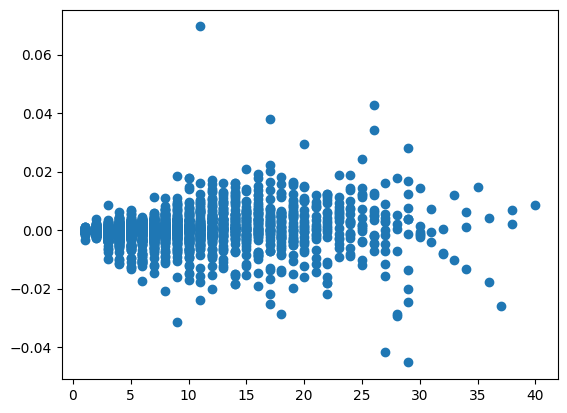

In [326]:
plt.scatter(merged_df['DBH'], merged_df['diff'])
plt.show()

In [327]:
species_df = merged_df.groupby('SPP')['diff'].mean().reset_index()

In [329]:
species_df = species_df.sort_values(by='diff')

In [330]:
species_df

,SPP,diff
13,Prunus cerasifera,-0.002309
11,Malus sylvestris,-0.001615
9,Gymnocladus dioicus,-0.001088
8,Gleditsia triacanthos,-0.000697
7,Fraxinus species,-0.000672
2,Celtis reticulata,-0.000603
14,Pyrus calleryana,-0.000535
17,Zelkova serrata,-0.000082
1,Acer platanoides,0.000035
15,Tilia cordata,0.000278


# Visuals

In [ ]:
# # Convert diff to numeric values
# diff_values = np.array(diff, dtype=float)

# # Map scientific names to common names
# tree_names = [
#     "Cherry Plum", "Green Ash", "Littleleaf Linden", "Honey Locust",
#     "Norway Maple", "Japanese Zelkova", "White Ash", "Golden Rain Tree",
#     "Siberian Elm", "Field Maple"
# ]

# # Reshape data for vertical plotting
# heatmap_data = diff_values.reshape(-1, 1)  # 10 rows and 1 column

# # Plotting
# plt.figure(figsize=(6, 10))  # Adjust figure size for vertical plot
# sns.heatmap(heatmap_data, annot=True, fmt=".6f", cmap="Blues", cbar=False,
#             yticklabels=tree_names, xticklabels=[], linewidths=0.5, annot_kws={"size": 12})

# # Adding titles and labels
# plt.title('Average Temperature Change by Species', fontsize=16)
# plt.ylabel('Tree Common Name', fontsize=14)
# plt.xlabel('Average Temperature Change (F°)', fontsize=14)
# plt.xticks(rotation=0, fontsize=12)

# # Display the plot
# plt.tight_layout()
# plt.show()